In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
TRACE_DIR = '/content/drive/MyDrive/paging_sim/traces'
os.makedirs(TRACE_DIR, exist_ok=True)
print("Saving traces to:", TRACE_DIR)

Mounted at /content/drive
Saving traces to: /content/drive/MyDrive/paging_sim/traces


In [ ]:
import numpy as np

def sequential(n=50000, start=0, stride=1, n_pages=10000):
    return [(start + i*stride) % n_pages for i in range(n)]

def strided(n=50000, stride=8, n_pages=10000):
    return sequential(n, 0, stride, n_pages)

def cyclic(n=50000, loop_len=20, start=100):
    loop = [start + i for i in range(loop_len)]
    return [loop[i % loop_len] for i in range(n)]

def clustered(n=50000, cluster_size=10, dwell=500, n_pages=10000, seed=0):
    rng = np.random.default_rng(seed)
    trace, i = [], 0
    while i < n:
        base = rng.integers(0, n_pages - cluster_size)
        for _ in range(min(dwell, n - i)):
            trace.append(int(base + rng.integers(0, cluster_size)))
            i += 1
    return trace

def uniform_random(n=50000, n_pages=10000, seed=0):
    rng = np.random.default_rng(seed)
    return rng.integers(0, n_pages, size=n).tolist()

def phase_changing(n=60000, seed=0):
    """Sequential -> cyclic -> random. This is your adaptive-layer test."""
    third = n // 3
    return (sequential(third, start=0, stride=1)
            + cyclic(third, loop_len=25, start=5000)
            + uniform_random(n - 2*third, seed=seed))

In [ ]:
import csv

TRACES = {
    'sequential':     sequential(),
    'strided':        strided(),
    'cyclic':         cyclic(),
    'clustered':      clustered(),
    'random':         uniform_random(),
    'phase_changing': phase_changing(),
}

for name, trace in TRACES.items():
    path = f'{TRACE_DIR}/{name}.csv'
    with open(path, 'w', newline='') as f:
        w = csv.writer(f)
        w.writerow(['access_id', 'page_id'])
        w.writerows(enumerate(trace))
    print(f'{name}: {len(trace)} accesses -> {path}')

sequential: 50000 accesses -> /content/drive/MyDrive/paging_sim/traces/sequential.csv
strided: 50000 accesses -> /content/drive/MyDrive/paging_sim/traces/strided.csv
cyclic: 50000 accesses -> /content/drive/MyDrive/paging_sim/traces/cyclic.csv
clustered: 50000 accesses -> /content/drive/MyDrive/paging_sim/traces/clustered.csv
random: 50000 accesses -> /content/drive/MyDrive/paging_sim/traces/random.csv
phase_changing: 60000 accesses -> /content/drive/MyDrive/paging_sim/traces/phase_changing.csv


# New Section

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = '/content/drive/MyDrive/paging_sim'
RAW  = f'{BASE}/raw'
OUT  = f'{BASE}/traces'
os.makedirs(RAW, exist_ok=True)
os.makedirs(OUT, exist_ok=True)
print('ready')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ready


In [ ]:
URL  = "https://utexas.box.com/shared/static/2yp1e4sr8am4brf4zq2kgsiseh2l84e3.xz"
NAME = "trace1.txt.xz"

!wget -O /content/{NAME} "{URL}"
!ls -lh /content/{NAME}

--2026-10-18 22:13:28--  https://utexas.box.com/shared/static/2yp1e4sr8am4brf4zq2kgsiseh2l84e3.xz
Resolving utexas.box.com (utexas.box.com)... 74.112.186.157, 2620:117:bff0:12d::
Connecting to utexas.box.com (utexas.box.com)|74.112.186.157|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: /public/static/2yp1e4sr8am4brf4zq2kgsiseh2l84e3.xz [following]
--2026-10-18 22:13:28--  https://utexas.box.com/public/static/2yp1e4sr8am4brf4zq2kgsiseh2l84e3.xz
Reusing existing connection to utexas.box.com:443.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://utexas.app.box.com/public/static/2yp1e4sr8am4brf4zq2kgsiseh2l84e3.xz [following]
--2026-10-18 22:13:28--  https://utexas.app.box.com/public/static/2yp1e4sr8am4brf4zq2kgsiseh2l84e3.xz
Resolving utexas.app.box.com (utexas.app.box.com)... 74.112.186.157, 2620:117:bff0:12d::
Connecting to utexas.app.box.com (utexas.app.box.com)|74.112.186.157|:443... connected.
HTTP request sent

In [ ]:
!file /content/{NAME}

/content/trace1.txt.xz: XZ compressed data, checksum CRC64


In [ ]:
!xz -dc /content/{NAME} 2>/dev/null | head -5

3, 13, fdfd3a8c1e00, 401a26, 0
5, 14, fdfd3a8c2800, 401a31, 0
17, 15, fdfd3a8c27c0, 401a65, 0
8, 16, a2132189e00, 401a3d, 0
13, 146, a213218ae00, 401a54, 0


In [ ]:
!cat ChampSim/download_links 2>/dev/null | head -30

In [ ]:
!git clone https://github.com/Quangmire/ChampSim.git
!ls ChampSim/download_links

Cloning into 'ChampSim'...
remote: Enumerating objects: 15005, done.
remote: Total 15005 (delta 0), reused 0 (delta 0), pack-reused 15005 (from 1)
Receiving objects: 100% (15005/15005), 4.00 MiB | 17.23 MiB/s, done.
Resolving deltas: 100% (10717/10717), done.
ChampSim/download_links


In [ ]:
!grep -i loadtrace ChampSim/download_links | head -40
!echo "--- total lines:"
!wc -l < ChampSim/download_links

ML-DPC/LoadTraces/gap/bc-0.txt.xz https://utexas.box.com/shared/static/6yqs1ju3dm41ehtkgtevpqtbntlirpvw.xz
ML-DPC/LoadTraces/gap/bc-12.txt.xz https://utexas.box.com/shared/static/2fq1dbabrnc5ursmtjtba8gf2qkwe8xt.xz
ML-DPC/LoadTraces/gap/bc-3.txt.xz https://utexas.box.com/shared/static/99zn5g3ygpzni5gqzmcbhy06igt4xajl.xz
ML-DPC/LoadTraces/gap/bc-5.txt.xz https://utexas.box.com/shared/static/6tek6jxvug3c5n0lx8vs61std3d7wupq.xz
ML-DPC/LoadTraces/gap/bfs-10.txt.xz https://utexas.box.com/shared/static/popgh0l7ho4uk4kwkwr47h3fecamxrcx.xz
ML-DPC/LoadTraces/gap/bfs-14.txt.xz https://utexas.box.com/shared/static/1t3g9prse46m1brsgnyofcxpql8hlobt.xz
ML-DPC/LoadTraces/gap/bfs-3.txt.xz https://utexas.box.com/shared/static/grztfufxb8ckb0k3god86ubzkyinuqh8.xz
ML-DPC/LoadTraces/gap/bfs-8.txt.xz https://utexas.box.com/shared/static/m5p0o03c2n2ngmdg9amzgq9h9pfnrokz.xz
ML-DPC/LoadTraces/gap/cc-13.txt.xz https://utexas.box.com/shared/static/9io1raatfqm54mmf8zlicoz4ti7uf0jf.xz
ML-DPC/LoadTraces/gap/cc-14.t

In [ ]:
URLS = {}
with open('ChampSim/download_links') as f:
    for line in f:
        parts = line.split()
        if len(parts) != 2 or 'LoadTraces' not in parts[0]:
            continue
        name = parts[0].split('/')[-1].replace('.txt.xz', '')
        URLS[name] = parts[1]

print(len(URLS), 'load traces found')
for k in sorted(URLS): print(' ', k)

99 load traces found
  410.bwaves-s0
  410.bwaves-s1
  410.bwaves-s2
  429.mcf-s0
  429.mcf-s1
  429.mcf-s2
  433.milc-s0
  433.milc-s1
  433.milc-s2
  437.leslie3d-s0
  437.leslie3d-s1
  437.leslie3d-s2
  450.soplex-s0
  450.soplex-s1
  450.soplex-s2
  459.GemsFDTD-s0
  459.GemsFDTD-s1
  459.GemsFDTD-s2
  462.libquantum-s0
  462.libquantum-s1
  462.libquantum-s2
  470.lbm-s0
  470.lbm-s1
  471.omnetpp-s0
  471.omnetpp-s1
  471.omnetpp-s2
  473.astar-s0
  473.astar-s1
  473.astar-s2
  482.sphinx3-s0
  482.sphinx3-s1
  482.sphinx3-s2
  602.gcc-s0
  602.gcc-s1
  602.gcc-s2
  602.gcc-s3
  605.mcf-s0
  605.mcf-s1
  605.mcf-s2
  605.mcf-s3
  605.mcf-s4
  605.mcf-s5
  605.mcf-s6
  605.mcf-s7
  605.mcf-s8
  619.lbm-s0
  619.lbm-s1
  619.lbm-s2
  619.lbm-s3
  620.omnetpp-s0
  620.omnetpp-s1
  621.wrf-s0
  621.wrf-s1
  621.wrf-s2
  621.wrf-s3
  623.xalancbmk-s0
  623.xalancbmk-s1
  623.xalancbmk-s2
  623.xalancbmk-s3
  623.xalancbmk-s4
  623.xalancbmk-s5
  649.fotonik3d-s0
  649.fotonik3d-s1
  

In [ ]:
import json
with open(f'{BASE}/trace_urls.json', 'w') as f:
    json.dump(URLS, f, indent=2)

In [ ]:
PICK = [
    '410.bwaves-s0',    # numerical, strided — you already have it
    '437.leslie3d-s0',  # CFD, regular but more complex than bwaves
    'bfs-3',            # graph traversal, irregular
    'pr-3',             # PageRank, irregular with some structure
]

In [ ]:
import csv, gzip, lzma

PAGE_SHIFT   = 12
MAX_ACCESSES = 500_000

def _open(path):
    if path.endswith('.xz'):  return lzma.open(path, 'rt')
    if path.endswith('.gz'):  return gzip.open(path, 'rt')
    return open(path, 'rt')

def convert(in_path, out_path, addr_col=2, is_hex=False,
            delimiter=None, limit=MAX_ACCESSES):
    n, skipped = 0, 0
    with _open(in_path) as fin, open(out_path, 'w', newline='') as fout:
        w = csv.writer(fout)
        w.writerow(['access_id', 'page_id'])
        for line in fin:
            parts = line.strip().split(delimiter)
            if len(parts) <= addr_col:
                skipped += 1
                continue
            raw = parts[addr_col].strip().rstrip(',')
            try:
                addr = int(raw, 16) if is_hex else int(raw)
            except ValueError:
                skipped += 1
                continue
            w.writerow([n, addr >> PAGE_SHIFT])
            n += 1
            if n >= limit:
                break
    return n, skipped

print('convert() ready')

convert() ready


In [ ]:
for v in ['BASE','RAW','OUT','URLS','PICK']:
    print(v, 'OK' if v in dir() else 'MISSING')

BASE OK
RAW OK
OUT OK
URLS OK
PICK OK


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, csv, gzip, lzma, json

BASE = '/content/drive/MyDrive/paging_sim'
RAW  = f'{BASE}/raw'
OUT  = f'{BASE}/traces'
os.makedirs(RAW, exist_ok=True); os.makedirs(OUT, exist_ok=True)

PAGE_SHIFT, MAX_ACCESSES = 12, 500_000

def _open(path):
    if path.endswith('.xz'): return lzma.open(path, 'rt')
    if path.endswith('.gz'): return gzip.open(path, 'rt')
    return open(path, 'rt')

def convert(in_path, out_path, addr_col=2, is_hex=True,
            delimiter=',', limit=MAX_ACCESSES):
    n, skipped = 0, 0
    with _open(in_path) as fin, open(out_path, 'w', newline='') as fout:
        w = csv.writer(fout); w.writerow(['access_id','page_id'])
        for line in fin:
            parts = line.strip().split(delimiter)
            if len(parts) <= addr_col: skipped += 1; continue
            try: addr = int(parts[addr_col].strip(), 16 if is_hex else 10)
            except ValueError: skipped += 1; continue
            w.writerow([n, addr >> PAGE_SHIFT]); n += 1
            if n >= limit: break
    return n, skipped

if not os.path.exists('ChampSim'):
    !git clone -q https://github.com/Quangmire/ChampSim.git

URLS = {}
with open('ChampSim/download_links') as f:
    for line in f:
        p = line.split()
        if len(p) == 2 and 'LoadTraces' in p[0]:
            URLS[p[0].split('/')[-1].replace('.txt.xz','')] = p[1]

with open(f'{BASE}/trace_urls.json','w') as f: json.dump(URLS, f, indent=2)

PICK = ['410.bwaves-s0', '437.leslie3d-s0', 'bfs-3', 'pr-3']
print(f'setup done — {len(URLS)} traces available, {len(PICK)} picked')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
setup done — 99 traces available, 4 picked


`

In [ ]:
for name in PICK:
    out_csv = f'{OUT}/{name}.csv'
    if os.path.exists(out_csv):
        print(f'{name:18s} already converted, skipping'); continue

    local = f'/content/{name}.txt.xz'
    if not os.path.exists(local):
        print(f'downloading {name} ...')
        !wget -q -O "{local}" "{URLS[name]}"

    try:
        with lzma.open(local,'rt') as f: first = f.readline().strip()
    except Exception as e:
        print(f'{name}: BAD DOWNLOAD ({e})'); continue

    mb = os.path.getsize(local)/1e6
    n, skipped = convert(local, out_csv)
    print(f'{name:18s} {mb:6.0f} MB -> {n:7d} accesses, {skipped} skipped')

!ls -lh {OUT}/

410.bwaves-s0      already converted, skipping
437.leslie3d-s0    already converted, skipping
bfs-3              already converted, skipping
pr-3               already converted, skipping
total 42M
-rw------- 1 root root 9.5M Sep 11 17:12 410.bwaves-s0.csv
-rw------- 1 root root 9.5M Sep 11 17:13 437.leslie3d-s0.csv
-rw------- 1 root root 9.4M Sep 11 17:13 bfs-3.csv
-rw------- 1 root root 570K Oct 18 22:13 clustered.csv
-rw------- 1 root root 527K Oct 18 22:13 cyclic.csv
-rw------- 1 root root 688K Oct 18 22:13 phase_changing.csv
-rw------- 1 root root 9.5M Sep 11 17:13 pr-3.csv
-rw------- 1 root root 570K Oct 18 22:13 random.csv
-rw------- 1 root root 570K Oct 18 22:13 sequential.csv
-rw------- 1 root root 570K Oct 18 22:13 strided.csv


In [ ]:
!rm -f /content/*.txt.xz
!df -h /content | tail -1

overlay         108G   21G   88G  20% /


In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

stats = []
for name in PICK:
    p = pd.read_csv(f'{OUT}/{name}.csv')['page_id'].values
    d = np.diff(p)
    vc = pd.Series(d).value_counts()
    stats.append({
        'trace': name,
        'accesses': len(p),
        'unique_pages': len(np.unique(p)),
        'reuse': round(len(p)/len(np.unique(p)), 2),
        'unique_deltas': len(vc),
        'top_delta': int(vc.index[0]),
        'top_delta_share': round(vc.iloc[0]/len(d), 3),
        'top5_share': round(vc.iloc[:5].sum()/len(d), 3),
    })

df = pd.DataFrame(stats)
display(df)

,trace,accesses,unique_pages,reuse,unique_deltas,top_delta,top_delta_share,top5_share
0,410.bwaves-s0,500000,7493,66.73,8209,1,0.674,0.799
1,437.leslie3d-s0,500000,4746,105.35,7285,0,0.248,0.545
2,bfs-3,500000,18826,26.56,40695,0,0.504,0.589
3,pr-3,500000,4510,110.86,35273,0,0.292,0.578


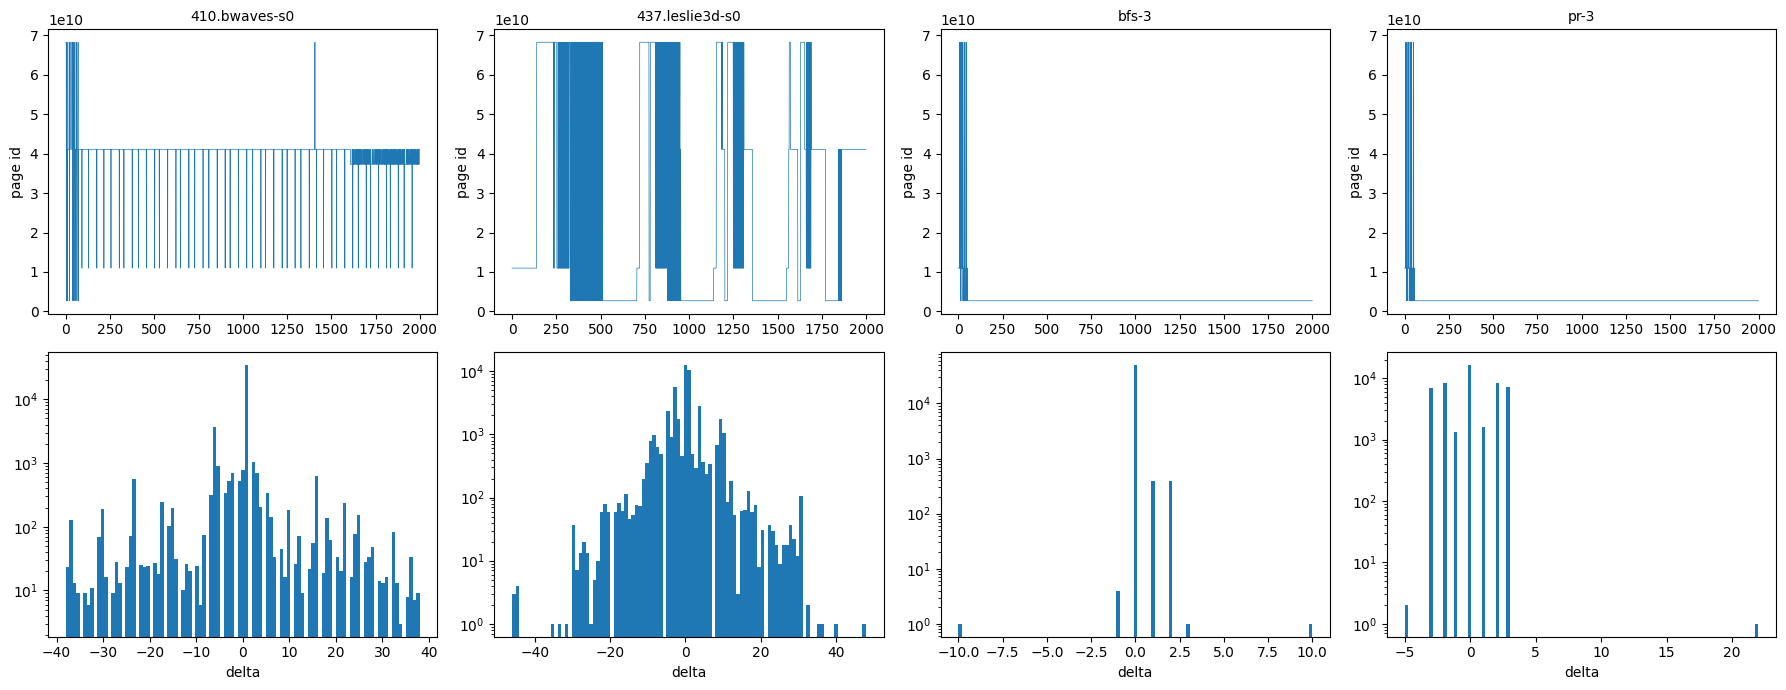

In [ ]:
fig, axes = plt.subplots(2, len(PICK), figsize=(4.5*len(PICK), 7))
for i, name in enumerate(PICK):
    p = pd.read_csv(f'{OUT}/{name}.csv')['page_id'].values
    axes[0,i].plot(p[:2000], lw=0.5)
    axes[0,i].set_title(name, fontsize=10); axes[0,i].set_ylabel('page id')

    d = np.diff(p[:50000])
    d = d[np.abs(d) < 50]
    axes[1,i].hist(d, bins=101)
    axes[1,i].set_xlabel('delta'); axes[1,i].set_yscale('log')
plt.tight_layout(); plt.show()

In [ ]:
df.to_csv(f'{BASE}/trace_characteristics.csv', index=False)
print('saved')


saved


In [ ]:
import pandas as pd, numpy as np

class Trace:
    """One workload, normalized. Knows nothing about where it came from."""

    def __init__(self, name, pages, train_frac=0.25):
        self.name   = name
        self.pages  = np.asarray(pages, dtype=np.int64)
        self.deltas = np.diff(self.pages, prepend=self.pages[0])
        self.split  = int(len(self.pages) * train_frac)

    # --- the two views ---
    @property
    def train(self):
        """Warm-up portion. Model may learn from this."""
        return self.pages[:self.split]

    @property
    def test(self):
        """Evaluation portion. Metrics measured only here."""
        return self.pages[self.split:]

    # --- streaming interface ---
    def stream(self, portion='all'):
        """Yield (index, page, delta) one at a time. No lookahead."""
        src = {'all': (0, len(self.pages)),
               'train': (0, self.split),
               'test': (self.split, len(self.pages))}[portion]
        for i in range(*src):
            yield i, int(self.pages[i]), int(self.deltas[i])

    def __len__(self):  return len(self.pages)
    def __repr__(self):
        return (f'<Trace {self.name}: {len(self)} accesses, '
                f'{len(np.unique(self.pages))} unique pages, '
                f'split@{self.split}>')


def load_trace(name, trace_dir=OUT, limit=None, train_frac=0.25):
    df = pd.read_csv(f'{trace_dir}/{name}.csv')
    pages = df['page_id'].values
    if limit: pages = pages[:limit]
    return Trace(name, pages, train_frac)

print('Trace loader ready')

Trace loader ready


In [ ]:
assert 'OUT' in globals(), 'Run the SETUP cell first'

In [ ]:

def load_trace(name, trace_dir=None, limit=None, train_frac=0.25):
    d = trace_dir or OUT          # resolved when called, not when defined
    df = pd.read_csv(f'{d}/{name}.csv')
    pages = df['page_id'].values
    if limit: pages = pages[:limit]
    return Trace(name, pages, train_frac)

In [ ]:
SYNTHETIC = ['sequential','strided','cyclic','clustered','random','phase_changing']
REAL      = PICK   # ['410.bwaves-s0','437.leslie3d-s0','bfs-3','pr-3']

import os
ALL_TRACES = [n for n in SYNTHETIC + REAL
              if os.path.exists(f'{OUT}/{n}.csv')]

print(f'{len(ALL_TRACES)} traces available:')
for n in ALL_TRACES: print('  ', n)

10 traces available:
   sequential
   strided
   cyclic
   clustered
   random
   phase_changing
   410.bwaves-s0
   437.leslie3d-s0
   bfs-3
   pr-3


In [ ]:
t = load_trace(ALL_TRACES[0], limit=50_000)
print(t)

# 1. lengths line up
assert len(t.pages) == len(t.deltas), 'delta/page length mismatch'
assert len(t.train) + len(t.test) == len(t), 'split loses accesses'

# 2. split is time-ordered, not shuffled
assert np.array_equal(np.concatenate([t.train, t.test]), t.pages), \
       'split reordered the sequence!'

# 3. deltas reconstruct the sequence
recon = np.cumsum(t.deltas) + t.pages[0] - t.deltas[0]
assert np.array_equal(recon, t.pages), 'deltas inconsistent'

# 4. streaming matches the array
streamed = [p for _, p, _ in t.stream()]
assert streamed == t.pages.tolist(), 'stream != pages'

print(f'train: {len(t.train)}  test: {len(t.test)}')
print('first 10 pages :', t.pages[:10].tolist())
print('first 10 deltas:', t.deltas[:10].tolist())
print('all checks passed')

<Trace sequential: 50000 accesses, 10000 unique pages, split@12500>
train: 12500  test: 37500
first 10 pages : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
first 10 deltas: [0, 1, 1, 1, 1, 1, 1, 1, 1, 1]
all checks passed


In [ ]:
#cell 1
from collections import OrderedDict


class MarkovPredictor:
    """Counts observed transitions. Bounded LRU table, top-K successors."""

    def __init__(self, capacity=16384, max_succ=4, order=1,
                 decay_every=50_000, min_count=1):
        self.capacity    = capacity
        self.max_succ    = max_succ
        self.order       = order
        self.decay_every = decay_every
        self.min_count   = min_count
        self.table       = OrderedDict()
        self.n_updates   = 0
        self.evictions   = 0

    def _key(self, history):
        if len(history) < self.order:
            return None
        return tuple(history[-self.order:])

    def update(self, history, actual_next):
        k = self._key(history)
        if k is None:
            return
        if k in self.table:
            self.table.move_to_end(k)
        else:
            if len(self.table) >= self.capacity:
                self.table.popitem(last=False)
                self.evictions += 1
            self.table[k] = {}

        succ = self.table[k]
        succ[actual_next] = succ.get(actual_next, 0) + 1
        if len(succ) > self.max_succ:
            del succ[min(succ, key=succ.get)]

        self.n_updates += 1
        if self.n_updates % self.decay_every == 0:
            self._decay()

    def _decay(self):
        for succ in self.table.values():
            for s in list(succ):
                succ[s] >>= 1
                if succ[s] == 0:
                    del succ[s]

    def predict(self, history, top_n=1):
        k = self._key(history)
        if k is None or k not in self.table:
            return []
        succ = self.table[k]
        total = sum(succ.values())
        if total == 0:
            return []
        ranked = sorted(succ.items(), key=lambda kv: -kv[1])[:top_n]
        return [(p, c / total) for p, c in ranked if c >= self.min_count]

    def stats(self):
        return {'entries': len(self.table),
                'evictions': self.evictions,
                'fill': round(len(self.table) / self.capacity, 3)}


class StridePredictor:
    """Predicts next = last + stride when recent deltas agree."""

    def __init__(self, confirm=3):
        self.confirm = confirm

    def predict(self, history, top_n=1):
        if len(history) < self.confirm + 1:
            return []
        d = [history[i] - history[i - 1] for i in range(-self.confirm, 0)]
        if len(set(d)) != 1 or d[0] == 0:
            return []
        return [(history[-1] + d[0], 1.0)]

    def update(self, history, actual_next):
        pass

    def stats(self):
        return {}


class HybridPredictor:
    """Order-2 Markov first, order-1 fallback, then stride."""

    def __init__(self, capacity=16384, max_succ=4, decay_every=50_000):
        self.m2 = MarkovPredictor(capacity, max_succ, order=2, decay_every=decay_every)
        self.m1 = MarkovPredictor(capacity, max_succ, order=1, decay_every=decay_every)
        self.st = StridePredictor()
        self.source_counts = {'m2': 0, 'm1': 0, 'stride': 0, 'none': 0}

    def predict(self, history, top_n=1):
        for tag, p in (('m2', self.m2), ('m1', self.m1), ('stride', self.st)):
            r = p.predict(history, top_n)
            if r:
                self.source_counts[tag] += 1
                return r
        self.source_counts['none'] += 1
        return []

    def update(self, history, actual_next):
        self.m2.update(history, actual_next)
        self.m1.update(history, actual_next)

    def stats(self):
        return {'sources': dict(self.source_counts), **self.m2.stats()}


print('predictors ready')

predictors ready


In [ ]:
#cell 2
def eval_predictor(trace, predictor, warmup_frac=0.25, hist_len=8):
    pages = trace.pages
    split = int(len(pages) * warmup_frac)
    history = []
    attempted = correct = no_pred = 0
    conf_sum = 0.0

    for i in range(len(pages) - 1):
        history.append(int(pages[i]))
        if len(history) > hist_len:
            history.pop(0)
        actual = int(pages[i+1])

        if i >= split:
            preds = predictor.predict(history, top_n=1)
            if not preds:
                no_pred += 1
            else:
                page, conf = preds[0]
                attempted += 1
                conf_sum += conf
                if page == actual:
                    correct += 1

        predictor.update(history, actual)

    n_eval   = max(1, len(pages) - 1 - split)
    coverage = attempted / n_eval
    accuracy = correct / attempted if attempted else 0.0
    return {
        'coverage':  coverage,
        'accuracy':  accuracy,
        'useful':    coverage * accuracy,      # combined score
        'mean_conf': conf_sum/attempted if attempted else 0.0,
        'extra':     predictor.stats(),
    }

In [ ]:
#cell 3 — rebuild TRACES as Trace objects
import os, pandas as pd, numpy as np, matplotlib.pyplot as plt

SYNTHETIC = ['sequential','strided','cyclic','clustered','random','phase_changing']
REAL      = PICK
ALL_TRACES = [n for n in SYNTHETIC + REAL if os.path.exists(f'{OUT}/{n}.csv')]

TRACES = {n: load_trace(n, limit=200_000) for n in ALL_TRACES}

assert all(hasattr(t, 'pages') for t in TRACES.values()), \
       'TRACES holds raw lists — check for a stray "TRACES =" assignment'
print(f'{len(TRACES)} Trace objects loaded')
for t in TRACES.values():
    print(' ', t)

10 Trace objects loaded
  <Trace sequential: 50000 accesses, 10000 unique pages, split@12500>
  <Trace strided: 50000 accesses, 1250 unique pages, split@12500>
  <Trace cyclic: 50000 accesses, 20 unique pages, split@12500>
  <Trace clustered: 50000 accesses, 908 unique pages, split@12500>
  <Trace random: 50000 accesses, 9930 unique pages, split@12500>
  <Trace phase_changing: 60000 accesses, 10000 unique pages, split@15000>
  <Trace 410.bwaves-s0: 200000 accesses, 3051 unique pages, split@50000>
  <Trace 437.leslie3d-s0: 200000 accesses, 2134 unique pages, split@50000>
  <Trace bfs-3: 200000 accesses, 5846 unique pages, split@50000>
  <Trace pr-3: 200000 accesses, 4062 unique pages, split@50000>


In [ ]:
#cell 4 — FROZEN HYPERPARAMETERS (single source of truth)
FROZEN = dict(capacity=256, max_succ=2, order=2, decay_every=25_000)

# Justification (from sweeps):
#   capacity=256  -> useful_real FLAT (0.783) from 256 to 4096; 16x memory
#                    buys nothing on real traces. 8.5 KB, ~2 pages,
#                    1.7% overhead at 128 frames.
#   max_succ=2    -> 2/4/8 differ by <0.0002; pick cheapest
#   order=2       -> beats order-1 by ~4.5 points (real effect)
#   decay=25000   -> marginally best, negligible cost

def make_predictor(kind):
    if kind == 'stride':    return StridePredictor()
    if kind == 'markov-o1': return MarkovPredictor(**{**FROZEN, 'order': 1})
    if kind == 'markov-o2': return MarkovPredictor(**FROZEN)
    if kind == 'hybrid':    return HybridPredictor(
                                capacity=FROZEN['capacity'],
                                max_succ=FROZEN['max_succ'],
                                decay_every=FROZEN['decay_every'])
    raise ValueError(kind)

KINDS = ['stride', 'markov-o1', 'markov-o2', 'hybrid']

import json
with open(f'{BASE}/frozen_config.json', 'w') as f:
    json.dump(FROZEN, f, indent=2)
print('FROZEN:', FROZEN)

FROZEN: {'capacity': 256, 'max_succ': 2, 'order': 2, 'decay_every': 25000}


In [ ]:
#cell 5 — coverage / accuracy / useful across all traces
assert all(hasattr(t, 'pages') for t in TRACES.values()), 're-run cell 3'

rows = []
for name, t in TRACES.items():
    kind_label = 'real' if name in REAL else 'synthetic'
    for k in KINDS:
        s = eval_predictor(t, make_predictor(k))
        rows.append({'trace': name, 'type': kind_label, 'predictor': k,
                     'coverage': round(s['coverage'], 3),
                     'accuracy': round(s['accuracy'], 3),
                     'useful':   round(s['useful'], 3)})

results = pd.DataFrame(rows)
results.to_csv(f'{BASE}/predictor_results.csv', index=False)

for metric in ['coverage', 'accuracy', 'useful']:
    print(f'\n===== {metric.upper()} =====')
    display(results.pivot(index='trace', columns='predictor', values=metric)[KINDS])

print('\n===== USEFUL (heatmap) =====')
display(results.pivot(index='trace', columns='predictor', values='useful')[KINDS]
        .style.background_gradient(cmap='RdYlGn', axis=None).format('{:.3f}'))


===== COVERAGE =====


predictor,stride,markov-o1,markov-o2,hybrid
trace,,,,
410.bwaves-s0,0.367,0.984,0.908,0.991
437.leslie3d-s0,0.038,0.984,0.926,0.984
bfs-3,0.000,0.963,0.850,0.963
clustered,0.002,0.981,0.799,0.982
cyclic,0.850,1.000,1.000,1.000
phase_changing,0.502,0.455,0.444,0.567
pr-3,0.000,0.970,0.927,0.970
random,0.000,0.025,0.000,0.025
sequential,1.000,0.000,0.000,1.000



===== ACCURACY =====


predictor,stride,markov-o1,markov-o2,hybrid
trace,,,,
410.bwaves-s0,0.697,0.800,0.838,0.811
437.leslie3d-s0,0.044,0.857,0.882,0.857
bfs-3,0.000,0.695,0.792,0.732
clustered,0.032,0.098,0.101,0.101
cyclic,0.941,1.000,1.000,1.000
phase_changing,0.965,0.976,1.000,0.980
pr-3,0.324,0.473,0.950,0.919
random,0.000,0.000,0.000,0.000
sequential,1.000,0.000,0.000,1.000



===== USEFUL =====


predictor,stride,markov-o1,markov-o2,hybrid
trace,,,,
410.bwaves-s0,0.256,0.788,0.761,0.804
437.leslie3d-s0,0.002,0.843,0.816,0.844
bfs-3,0.000,0.669,0.673,0.706
clustered,0.000,0.097,0.081,0.099
cyclic,0.800,1.000,1.000,1.000
phase_changing,0.484,0.444,0.444,0.555
pr-3,0.000,0.458,0.881,0.892
random,0.000,0.000,0.000,0.000
sequential,1.000,0.000,0.000,1.000



===== USEFUL (heatmap) =====


predictor,stride,markov-o1,markov-o2,hybrid
trace,,,,
410.bwaves-s0,0.256,0.788,0.761,0.804
437.leslie3d-s0,0.002,0.843,0.816,0.844
bfs-3,0.000,0.669,0.673,0.706
clustered,0.000,0.097,0.081,0.099
cyclic,0.800,1.000,1.000,1.000
phase_changing,0.484,0.444,0.444,0.555
pr-3,0.000,0.458,0.881,0.892
random,0.000,0.000,0.000,0.000
sequential,1.000,0.000,0.000,1.000


In [ ]:
FROZEN = dict(capacity=256, max_succ=2, order=2, decay_every=25_000)

sequential         m2=0%  m1=0%  stride=100%  none=0%
strided            m2=0%  m1=0%  stride=100%  none=0%
cyclic             m2=100%  m1=0%  stride=0%  none=0%
clustered          m2=80%  m1=18%  stride=0%  none=2%
random             m2=0%  m1=3%  stride=0%  none=97%
phase_changing     m2=44%  m1=1%  stride=11%  none=43%
410.bwaves-s0      m2=91%  m1=8%  stride=1%  none=1%
437.leslie3d-s0    m2=93%  m1=6%  stride=0%  none=2%
bfs-3              m2=85%  m1=11%  stride=0%  none=4%
pr-3               m2=93%  m1=4%  stride=0%  none=3%


,m2,m1,stride,none
trace,,,,
sequential,0.000,0.000,1.000,0.000
strided,0.000,0.000,0.998,0.002
cyclic,1.000,0.000,0.000,0.000
clustered,0.799,0.182,0.000,0.018
random,0.000,0.025,0.000,0.975
phase_changing,0.444,0.011,0.112,0.433
410.bwaves-s0,0.908,0.076,0.006,0.009
437.leslie3d-s0,0.926,0.058,0.001,0.016
bfs-3,0.850,0.113,0.000,0.037


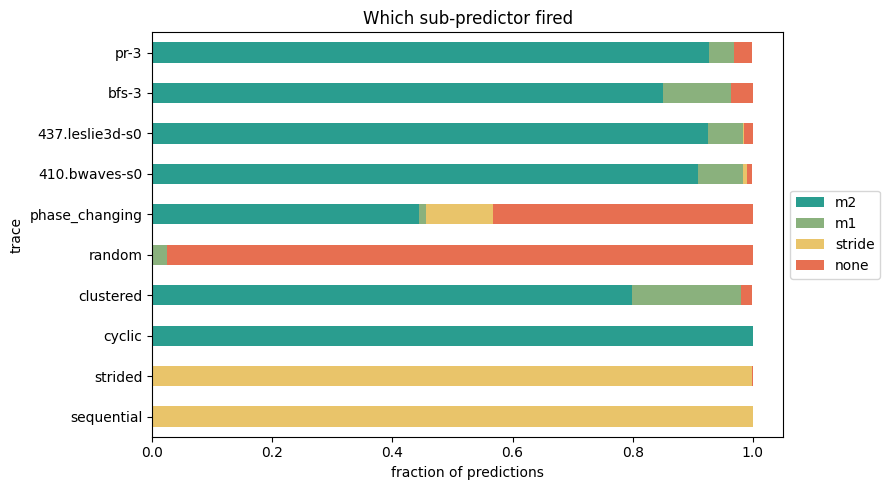

In [ ]:
#cell 6 — which sub-predictor fired
attrib = []
for name, t in TRACES.items():
    h = make_predictor('hybrid')
    eval_predictor(t, h)
    src = h.stats()['sources']
    tot = max(1, sum(src.values()))
    print(f"{name:18s} " + "  ".join(f"{k}={v/tot:.0%}" for k, v in src.items()))
    attrib.append({'trace': name, **{k: round(v/tot, 3) for k, v in src.items()}})

att = pd.DataFrame(attrib).set_index('trace')
att.to_csv(f'{BASE}/predictor_attribution.csv')
display(att)

att[['m2','m1','stride','none']].plot(
    kind='barh', stacked=True, figsize=(9,5),
    color=['#2a9d8f','#8ab17d','#e9c46a','#e76f51'])
plt.xlabel('fraction of predictions'); plt.title('Which sub-predictor fired')
plt.legend(loc='center left', bbox_to_anchor=(1,0.5))
plt.tight_layout(); plt.show()

In [ ]:
  #cell 7 — memory footprint (information-theoretic, not Python overhead)
CTX_BYTES  = FROZEN['order'] * 8    # 64-bit page numbers
SUCC_BYTES = 9                      # 8B page + 1B saturating counter

MAX_BYTES = (FROZEN['capacity'] * CTX_BYTES
             + FROZEN['capacity'] * FROZEN['max_succ'] * SUCC_BYTES)

foot = []
for name, t in TRACES.items():
    m = MarkovPredictor(**FROZEN)
    eval_predictor(t, m)
    n_ctx  = len(m.table)
    n_succ = sum(len(s) for s in m.table.values())
    raw_b  = n_ctx*CTX_BYTES + n_succ*SUCC_BYTES
    foot.append({'trace': name, 'contexts': n_ctx, 'successors': n_succ,
                 'succ_per_ctx': round(n_succ/n_ctx, 2) if n_ctx else 0,
                 'evictions': m.evictions,
                 'table_KB': round(raw_b/1024, 1),
                 'equiv_4K_pages': round(raw_b/4096, 1),
                 'pct_of_max': round(100*raw_b/MAX_BYTES, 1)})

fp = pd.DataFrame(foot)
display(fp)
fp.to_csv(f'{BASE}/memory_footprint.csv', index=False)

print(f"\nconfig: capacity={FROZEN['capacity']}, order={FROZEN['order']}, "
      f"max_succ={FROZEN['max_succ']}")
print(f"bounded ceiling : {MAX_BYTES/1024:.1f} KB (~{MAX_BYTES/4096:.1f} pages)")
print(f"observed max    : {fp.table_KB.max():.1f} KB")
print(f"observed mean   : {fp.table_KB.mean():.1f} KB")

print('\noverhead as % of simulated RAM:')
print(f"{'frames':>8} {'RAM_KB':>9} {'overhead_%':>11}")
for frames in [128, 256, 512, 1024]:
    print(f"{frames:>8} {frames*4:>9} {100*MAX_BYTES/1024/(frames*4):>10.2f}%")

,trace,contexts,successors,succ_per_ctx,evictions,table_KB,equiv_4K_pages,pct_of_max
0,sequential,256,256,1.00,49742,6.2,1.6,73.5
1,strided,256,256,1.00,49742,6.2,1.6,73.5
2,cyclic,20,20,1.00,0,0.5,0.1,5.7
3,clustered,256,500,1.95,9768,8.4,2.1,98.8
4,random,256,256,1.00,49742,6.2,1.6,73.5
5,phase_changing,256,256,1.00,39768,6.2,1.6,73.5
6,410.bwaves-s0,256,340,1.33,18074,7.0,1.7,82.2
7,437.leslie3d-s0,256,339,1.32,14640,7.0,1.7,82.1
8,bfs-3,256,363,1.42,23820,7.2,1.8,84.6
9,pr-3,256,282,1.10,13289,6.5,1.6,76.2



config: capacity=256, order=2, max_succ=2
bounded ceiling : 8.5 KB (~2.1 pages)
observed max    : 8.4 KB
observed mean   : 6.1 KB

overhead as % of simulated RAM:
  frames    RAM_KB  overhead_%
     128       512       1.66%
     256      1024       0.83%
     512      2048       0.42%
    1024      4096       0.21%


,capacity,table_KB,pages,useful_real,useful_all,ovh_128f,ovh_512f
0,128,4.2,1.1,0.783,0.466,0.8%,0.2%
1,256,8.5,2.1,0.783,0.466,1.7%,0.4%
2,512,17.0,4.2,0.783,0.466,3.3%,0.8%
3,1024,34.0,8.5,0.783,0.466,6.6%,1.7%
4,2048,68.0,17.0,0.783,0.566,13.3%,3.3%
5,4096,136.0,34.0,0.783,0.566,26.6%,6.6%


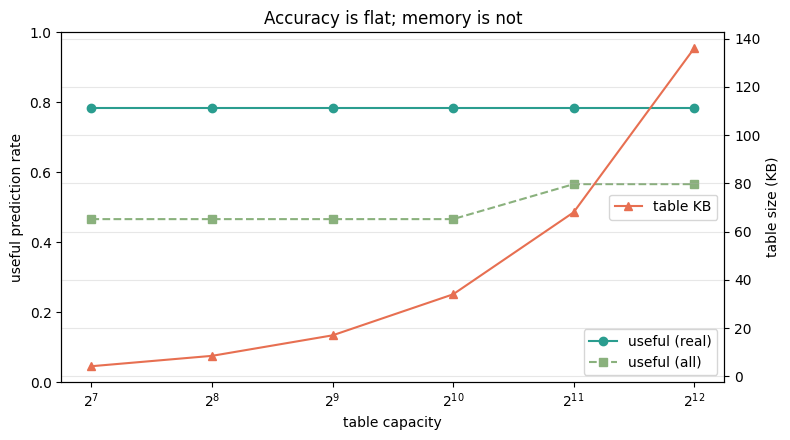

In [ ]:
#cell 8 — capacity vs accuracy vs overhead
rows = []
for cap in [128, 256, 512, 1024, 2048, 4096]:
    cfg   = {**FROZEN, 'capacity': cap}
    max_b = cap*CTX_BYTES + cap*cfg['max_succ']*SUCC_BYTES
    real_s, all_s = [], []
    for name, t in TRACES.items():
        u = eval_predictor(t, MarkovPredictor(**cfg))['useful']
        all_s.append(u)
        if name in REAL: real_s.append(u)
    rows.append({'capacity': cap, 'table_KB': round(max_b/1024,1),
                 'pages': round(max_b/4096,1),
                 'useful_real': round(np.mean(real_s),3),
                 'useful_all':  round(np.mean(all_s),3),
                 'ovh_128f': f"{100*max_b/1024/512:.1f}%",
                 'ovh_512f': f"{100*max_b/1024/2048:.1f}%"})

sw = pd.DataFrame(rows)
display(sw)
sw.to_csv(f'{BASE}/capacity_sweep.csv', index=False)

fig, ax1 = plt.subplots(figsize=(8,4.5))
ax1.plot(sw.capacity, sw.useful_real, 'o-', color='#2a9d8f', label='useful (real)')
ax1.plot(sw.capacity, sw.useful_all,  's--', color='#8ab17d', label='useful (all)')
ax1.set_xscale('log', base=2); ax1.set_xlabel('table capacity')
ax1.set_ylabel('useful prediction rate'); ax1.set_ylim(0,1)
ax2 = ax1.twinx()
ax2.plot(sw.capacity, sw.table_KB, '^-', color='#e76f51', label='table KB')
ax2.set_ylabel('table size (KB)')
ax1.legend(loc='lower right'); ax2.legend(loc='center right')
plt.title('Accuracy is flat; memory is not'); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

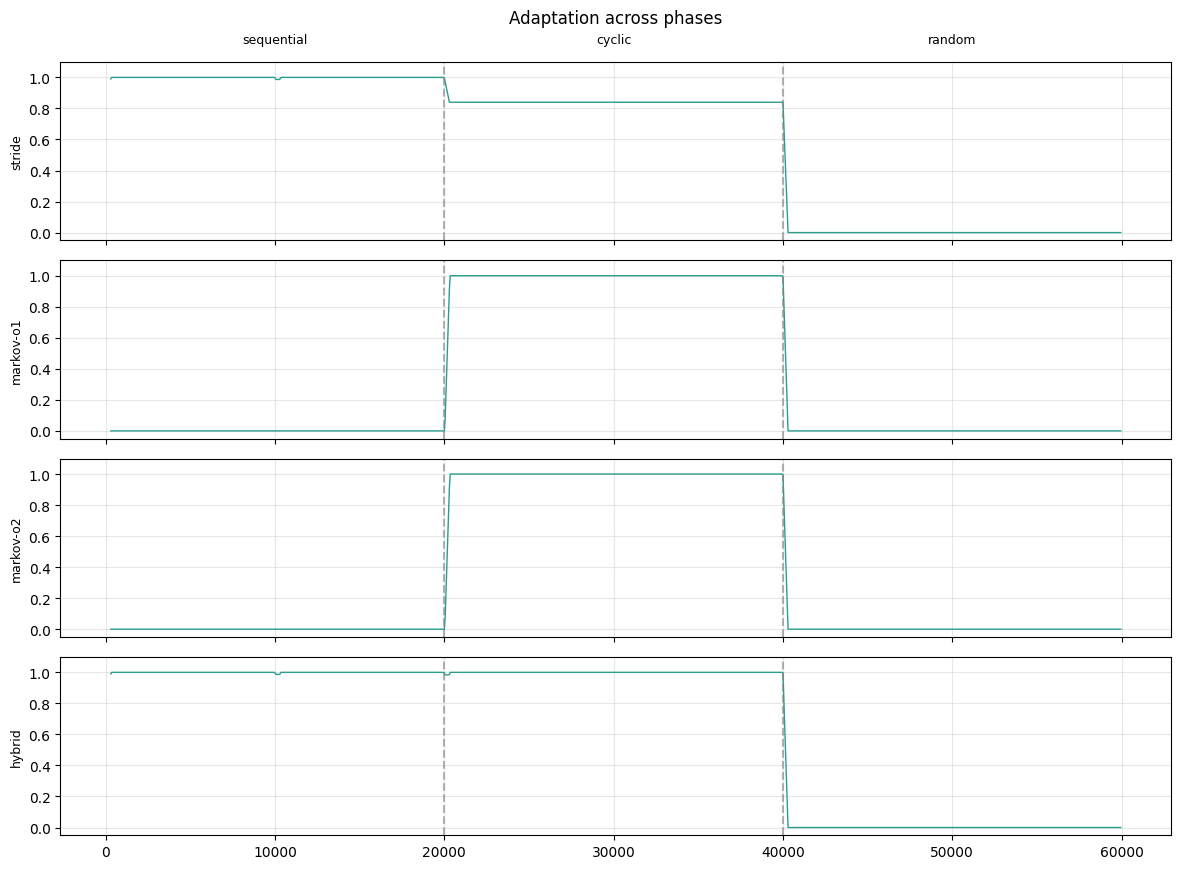

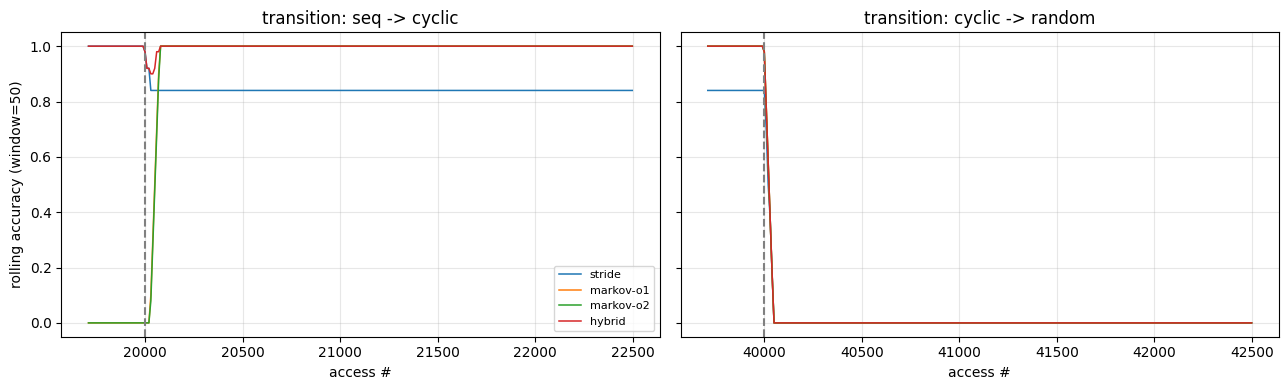

accesses to reach 90% of post-transition plateau:
predictor      seq->cyclic   cyclic->random
stride                   9                9
markov-o1               69                9
markov-o2               79                9
hybrid                   9                9


In [ ]:
  #cell 9 — adaptation across workload phases
def rolling_accuracy(trace, predictor, window=300, warmup_frac=0.0,
                     hist_len=8, step=50):
    pages = trace.pages
    split = int(len(pages) * warmup_frac)
    hist, hits, xs, ys = [], [], [], []
    for i in range(len(pages) - 1):
        hist.append(int(pages[i]))
        if len(hist) > hist_len:
            hist.pop(0)
        actual = int(pages[i + 1])
        if i >= split:
            p = predictor.predict(hist, top_n=1)
            hits.append(1 if (p and p[0][0] == actual) else 0)
            if len(hits) >= window and len(hits) % step == 0:
                xs.append(i)
                ys.append(np.mean(hits[-window:]))
        predictor.update(hist, actual)
    return xs, ys


t = TRACES['phase_changing']
n = len(t.pages)
b1, b2 = n // 3, 2 * n // 3

# ---- per-predictor panels (avoids overplotting) ----
fig, axes = plt.subplots(len(KINDS), 1, figsize=(12, 2.2 * len(KINDS)),
                         sharex=True, sharey=True)
for ax, k in zip(axes, KINDS):
    xs, ys = rolling_accuracy(t, make_predictor(k))
    ax.plot(xs, ys, lw=1.0, color='#2a9d8f')
    ax.axvline(b1, ls='--', c='gray', alpha=.6)
    ax.axvline(b2, ls='--', c='gray', alpha=.6)
    ax.set_ylim(-.05, 1.1)
    ax.set_ylabel(k, fontsize=9)
    ax.grid(alpha=.3)

axes[0].set_title('Adaptation across phases', pad=28)
axes[0].text(b1/2,      1.22, 'sequential', ha='center', fontsize=9)
axes[0].text((b1+b2)/2, 1.22, 'cyclic',     ha='center', fontsize=9)
axes[0].text((b2+n)/2,  1.22, 'random',     ha='center', fontsize=9)
plt.tight_layout()
plt.savefig(f'{BASE}/phase_adaptation.png', dpi=150, bbox_inches='tight')
plt.show()


# ---- zoom: how fast does each predictor recover after a phase change? ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (b, label) in zip(axes, [(b1, 'seq -> cyclic'), (b2, 'cyclic -> random')]):
    for k in KINDS:
        xs, ys = rolling_accuracy(t, make_predictor(k), window=50, step=10)
        pts = [(x, y) for x, y in zip(xs, ys) if b - 300 < x < b + 2500]
        if pts:
            ax.plot([p[0] for p in pts], [p[1] for p in pts], lw=1.1, label=k)
    ax.axvline(b, ls='--', c='gray')
    ax.set_title(f'transition: {label}')
    ax.set_xlabel('access #')
    ax.grid(alpha=.3)
axes[0].set_ylabel('rolling accuracy (window=50)')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(f'{BASE}/phase_recovery_zoom.png', dpi=150, bbox_inches='tight')
plt.show()


# ---- quantify recovery time ----
def recovery_time(trace, predictor, boundary, window=50, step=10,
                  target=0.9, lookahead=5000):
    xs, ys = rolling_accuracy(trace, predictor, window=window, step=step)
    post = [(x, y) for x, y in zip(xs, ys) if boundary <= x <= boundary + lookahead]
    if not post:
        return None
    plateau = max(y for _, y in post)
    if plateau <= 0:
        return 0
    for x, y in post:
        if y >= target * plateau:
            return x - boundary
    return None

print('accesses to reach 90% of post-transition plateau:')
print(f"{'predictor':<12}{'seq->cyclic':>14}{'cyclic->random':>17}")
for k in KINDS:
    r1 = recovery_time(t, make_predictor(k), b1)
    r2 = recovery_time(t, make_predictor(k), b2)
    f = lambda r: 'n/a' if r is None else str(r)
    print(f'{k:<12}{f(r1):>14}{f(r2):>17}')

In [ ]:
#cell 9b
# ===== capacity vs overhead tradeoff =====
import pandas as pd, numpy as np

rows = []
for cap in [256, 512, 1024, 2048, 4096]:
    cfg = {**FROZEN, 'capacity': cap}
    max_b = cap*CTX_BYTES + cap*cfg['max_succ']*SUCC_BYTES

    real_scores, all_scores = [], []
    for name, t in TRACES.items():
        u = eval_predictor(t, MarkovPredictor(**cfg))['useful']
        all_scores.append(u)
        if name in REAL:
            real_scores.append(u)

    rows.append({
        'capacity':    cap,
        'table_KB':    round(max_b/1024, 1),
        'pages':       round(max_b/4096, 1),
        'useful_real': round(np.mean(real_scores), 3),
        'useful_all':  round(np.mean(all_scores), 3),
        'ovh_128f':    f"{100*max_b/1024/(128*4):.1f}%",
        'ovh_512f':    f"{100*max_b/1024/(512*4):.1f}%",
    })

display(pd.DataFrame(rows))

,capacity,table_KB,pages,useful_real,useful_all,ovh_128f,ovh_512f
0,256,8.5,2.1,0.783,0.466,1.7%,0.4%
1,512,17.0,4.2,0.783,0.466,3.3%,0.8%
2,1024,34.0,8.5,0.783,0.466,6.6%,1.7%
3,2048,68.0,17.0,0.783,0.566,13.3%,3.3%
4,4096,136.0,34.0,0.783,0.566,26.6%,6.6%


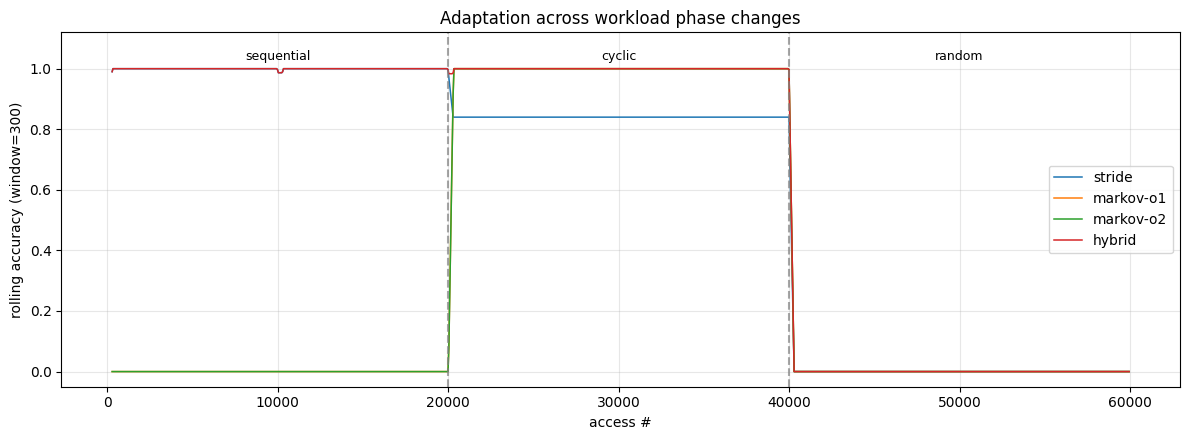

In [ ]:
def rolling_accuracy(trace, predictor, window=300, warmup_frac=0.0,
                     hist_len=8, step=50):
    pages = trace.pages
    split = int(len(pages) * warmup_frac)
    hist, hits, xs, ys = [], [], [], []
    for i in range(len(pages) - 1):
        hist.append(int(pages[i]))
        if len(hist) > hist_len:
            hist.pop(0)
        actual = int(pages[i + 1])
        if i >= split:
            p = predictor.predict(hist, top_n=1)
            hits.append(1 if (p and p[0][0] == actual) else 0)
            if len(hits) >= window and len(hits) % step == 0:
                xs.append(i)
                ys.append(np.mean(hits[-window:]))
        predictor.update(hist, actual)
    return xs, ys


t = TRACES['phase_changing']
n = len(t.pages)
b1, b2 = n // 3, 2 * n // 3          # actual generator boundaries

plt.figure(figsize=(12, 4.5))
for k in ['stride', 'markov-o1', 'markov-o2', 'hybrid']:
    xs, ys = rolling_accuracy(t, make_predictor(k))
    plt.plot(xs, ys, label=k, lw=1.1)

plt.axvline(b1, ls='--', c='gray', alpha=.7)
plt.axvline(b2, ls='--', c='gray', alpha=.7)
plt.text(b1/2,        1.03, 'sequential', ha='center', fontsize=9)
plt.text((b1+b2)/2,   1.03, 'cyclic',     ha='center', fontsize=9)
plt.text((b2+n)/2,    1.03, 'random',     ha='center', fontsize=9)

plt.ylim(-0.05, 1.12)
plt.xlabel('access #'); plt.ylabel(f'rolling accuracy (window=300)')
plt.legend(loc='center right'); plt.grid(alpha=.3)
plt.title('Adaptation across workload phase changes')
plt.tight_layout(); plt.show()

In [ ]:
#cell 10 — save summary
summary = {
    'frozen_config':  FROZEN,
    'n_traces':       len(TRACES),
    'real_traces':    REAL,
    'synthetic':      SYNTHETIC,
    'table_KB':       round(MAX_BYTES/1024, 1),
    'overhead_128f':  f"{100*MAX_BYTES/1024/512:.2f}%",
    'hybrid_mean_useful_real': float(
        results[(results.predictor=='hybrid') & (results.type=='real')].useful.mean()),
    'hybrid_mean_useful_all': float(
        results[results.predictor=='hybrid'].useful.mean()),
}
with open(f'{BASE}/stage3_summary.json','w') as f:
    json.dump(summary, f, indent=2, default=str)
print(json.dumps(summary, indent=2, default=str))
!ls -la {BASE}/*.csv {BASE}/*.json

{
  "frozen_config": {
    "capacity": 256,
    "max_succ": 2,
    "order": 2,
    "decay_every": 25000
  },
  "n_traces": 10,
  "real_traces": [
    "410.bwaves-s0",
    "437.leslie3d-s0",
    "bfs-3",
    "pr-3"
  ],
  "synthetic": [
    "sequential",
    "strided",
    "cyclic",
    "clustered",
    "random",
    "phase_changing"
  ],
  "table_KB": 8.5,
  "overhead_128f": "1.66%",
  "hybrid_mean_useful_real": 0.8115,
  "hybrid_mean_useful_all": 0.6897000000000001
}
-rw------- 1 root root 6058 Sep 22 16:33 /content/drive/MyDrive/paging_sim/ablation_results.csv
-rw------- 1 root root 7972 Sep 22 16:30 /content/drive/MyDrive/paging_sim/baseline_results.csv
-rw------- 1 root root  281 Oct 18 22:14 /content/drive/MyDrive/paging_sim/capacity_sweep.csv
-rw------- 1 root root  364 Sep 22 16:33 /content/drive/MyDrive/paging_sim/decider_summary.csv
-rw------- 1 root root   76 Oct 18 22:13 /content/drive/MyDrive/paging_sim/frozen_config.json
-rw------- 1 root root 1092 Sep 22 16:33 /content/dr

In [ ]:
#cell 11 — policy-agnostic memory engine
from collections import OrderedDict, deque

class MemoryEngine:
    """Page table + frame table + fault handler. Knows nothing about policy."""

    def __init__(self, n_frames, policy):
        self.n_frames = n_frames
        self.policy   = policy          # pluggable eviction policy
        self.resident = set()           # pages currently in RAM
        self.reset_stats()

    def reset_stats(self):
        self.n_access   = 0
        self.n_fault    = 0
        self.n_evict    = 0
        # prefetch bookkeeping (unused by baselines)
        self.prefetched = {}            # page -> still-unused flag
        self.n_prefetch = 0
        self.n_pf_used  = 0
        self.n_pf_wasted= 0

    # ---- the ONLY way a page enters RAM ----
    def _install(self, page, i, is_prefetch=False):
        if page in self.resident:
            return
        if len(self.resident) >= self.n_frames:
            victim = self.policy.choose_victim(self.resident, i)
            self.resident.discard(victim)
            self.policy.on_evict(victim)
            self.n_evict += 1
            if self.prefetched.pop(victim, False):
                self.n_pf_wasted += 1      # prefetched but never used
        self.resident.add(page)
        self.policy.on_insert(page, i)
        if is_prefetch:
            self.prefetched[page] = True
            self.n_prefetch += 1

    def access(self, page, i):
        """Demand access. Returns True if it was a fault."""
        self.n_access += 1
        hit = page in self.resident

        if self.prefetched.pop(page, False):
            self.n_pf_used += 1            # a prefetch paid off

        if hit:
            self.policy.on_hit(page, i)
            return False

        self.n_fault += 1
        self._install(page, i, is_prefetch=False)
        return True

    def prefetch(self, page, i):
        """Speculative load. Never bypasses the fault handler."""
        if page in self.resident:
            return False
        self._install(page, i, is_prefetch=True)
        return True

    def stats(self):
        return {
            'accesses':     self.n_access,
            'faults':       self.n_fault,
            'fault_rate':   self.n_fault / max(1, self.n_access),
            'evictions':    self.n_evict,
            'prefetches':   self.n_prefetch,
            'pf_used':      self.n_pf_used,
            'pf_wasted':    self.n_pf_wasted,
            'pf_precision': self.n_pf_used / max(1, self.n_prefetch),
        }

print('MemoryEngine ready')

MemoryEngine ready


In [ ]:
#cell 12 — eviction policies
class FIFO:
    def __init__(self, **kw): self.q = deque()
    def on_insert(self, page, i): self.q.append(page)
    def on_hit(self, page, i):    pass
    def on_evict(self, page):     pass
    def choose_victim(self, resident, i):
        while self.q:
            p = self.q.popleft()
            if p in resident:
                return p
        return next(iter(resident))

class LRU:
    def __init__(self, **kw): self.od = OrderedDict()
    def on_insert(self, page, i): self.od[page] = i; self.od.move_to_end(page)
    def on_hit(self, page, i):    self.od[page] = i; self.od.move_to_end(page)
    def on_evict(self, page):     self.od.pop(page, None)
    def choose_victim(self, resident, i):
        for p in self.od:
            if p in resident:
                return p
        return next(iter(resident))

class Clock:
    """Second-chance approximation of LRU."""
    def __init__(self, **kw):
        self.ring, self.ref, self.hand = [], {}, 0
    def on_insert(self, page, i):
        self.ring.append(page); self.ref[page] = 1
    def on_hit(self, page, i):    self.ref[page] = 1
    def on_evict(self, page):
        if page in self.ring:
            idx = self.ring.index(page)
            self.ring.pop(idx); self.ref.pop(page, None)
            if self.hand > idx: self.hand -= 1
    def choose_victim(self, resident, i):
        while True:
            if not self.ring: return next(iter(resident))
            self.hand %= len(self.ring)
            p = self.ring[self.hand]
            if p not in resident:
                self.ring.pop(self.hand); self.ref.pop(p, None); continue
            if self.ref.get(p, 0) == 0:
                return p
            self.ref[p] = 0
            self.hand += 1

class OPT:
    """Belady's optimal. ALLOWED to see the future — it is the lower bound."""
    def __init__(self, pages=None, **kw):
        self.pages = pages
        self.next_use = self._build(pages)
    def _build(self, pages):
        nxt = [None]*len(pages)
        last = {}
        for i in range(len(pages)-1, -1, -1):
            p = int(pages[i])
            nxt[i] = last.get(p, float('inf'))
            last[p] = i
        self.future = {}
        return nxt
    def on_insert(self, page, i): pass
    def on_hit(self, page, i):    pass
    def on_evict(self, page):     pass
    def choose_victim(self, resident, i):
        best, best_d = None, -1
        for p in resident:
            d = self._next_occurrence(p, i)
            if d > best_d:
                best, best_d = p, d
        return best
    def _next_occurrence(self, page, i):
        arr = self.pages
        for j in range(i+1, len(arr)):
            if int(arr[j]) == page:
                return j
        return float('inf')

print('policies ready')

policies ready


In [ ]:
#cell 12b — fast OPT
class OPTFast:
    """Belady's optimal with precomputed occurrence lists."""
    def __init__(self, pages=None, **kw):
        from collections import defaultdict
        import bisect
        self.occ = defaultdict(list)
        for i, p in enumerate(pages):
            self.occ[int(p)].append(i)
        self.bisect = bisect
    def on_insert(self, page, i): pass
    def on_hit(self, page, i):    pass
    def on_evict(self, page):     pass
    def choose_victim(self, resident, i):
        best, best_d = None, -1
        for p in resident:
            lst = self.occ.get(p, [])
            k = self.bisect.bisect_right(lst, i)
            d = lst[k] if k < len(lst) else float('inf')
            if d > best_d:
                best, best_d = p, d
                if d == float('inf'):
                    break            # never used again — evict immediately
        return best

In [ ]:
#cell 13 — baseline comparison, frames scaled to working set
POLICIES = {'FIFO': FIFO, 'LRU': LRU, 'Clock': Clock, 'OPT': OPTFast}
RATIOS   = [0.01, 0.02, 0.05, 0.10, 0.25]   # fraction of working set

rows = []
for name, t in TRACES.items():
    ws = len(np.unique(t.pages))
    for r in RATIOS:
        nf = max(8, int(ws * r))
        for pname, P in POLICIES.items():
            eng = MemoryEngine(nf, P(pages=t.pages))
            for i, page, _ in t.stream():
                eng.access(page, i)
            s = eng.stats()
            rows.append({'trace': name, 'ws': ws, 'ratio': r, 'frames': nf,
                         'policy': pname, 'faults': s['faults'],
                         'fault_rate': round(s['fault_rate'], 4)})

base = pd.DataFrame(rows)
base.to_csv(f'{BASE}/baseline_results.csv', index=False)
display(base.pivot_table(index=['trace','ratio','frames'], columns='policy',
                         values='fault_rate')[['FIFO','LRU','Clock','OPT']])

piv = base.pivot_table(index=['trace','frames'], columns='policy', values='faults')
print('any policy beating OPT?')
for pol in ['FIFO','LRU','Clock']:
    bad = piv[piv[pol] < piv['OPT']]
    print(f'  {pol}: {len(bad)} violations')

policy                          FIFO     LRU   Clock     OPT
trace           ratio frames                                
410.bwaves-s0   0.01  30      0.0169  0.0157  0.0161  0.0156
                0.02  61      0.0157  0.0157  0.0157  0.0154
                0.05  152     0.0157  0.0157  0.0157  0.0153
                0.10  305     0.0157  0.0157  0.0157  0.0153
                0.25  762     0.0157  0.0157  0.0157  0.0153
437.leslie3d-s0 0.01  21      0.0780  0.0766  0.0756  0.0294
                0.02  42      0.0167  0.0197  0.0166  0.0161
                0.05  106     0.0164  0.0164  0.0164  0.0149
                0.10  213     0.0164  0.0164  0.0164  0.0133
                0.25  533     0.0164  0.0164  0.0164  0.0107
bfs-3           0.01  58      0.0348  0.0338  0.0340  0.0309
                0.02  116     0.0335  0.0323  0.0323  0.0306
                0.05  292     0.0323  0.0314  0.0314  0.0297
                0.10  584     0.0318  0.0312  0.0312  0.0292
                0.25  1461    0.0312  0.0310  0.0310  0.0292
clustered       0.01  9       0.1146  0.1161  0.1135  0.0527
                0.02  18      0.0200  0.0200  0.0200  0.0195
                0.05  45      0.0199  0.0199  0.0199  0.0185
                0.10  90      0.0199  0.0199  0.0199  0.0182
                0.25  227     0.0190  0.0190  0.0190  0.0182
cyclic          0.01  8       1.0000  1.0000  1.0000  0.6317
                0.02  8       1.0000  1.0000  1.0000  0.6317
                0.05  8       1.0000  1.0000  1.0000  0.6317
                0.10  8       1.0000  1.0000  1.0000  0.6317
                0.25  8       1.0000  1.0000  1.0000  0.6317
phase_changing  0.01  100     0.6633  0.6633  0.6633  0.6209
                0.02  200     0.6604  0.6603  0.6603  0.6005
                0.05  500     0.6503  0.6503  0.6503  0.5591
                0.10  1000    0.6325  0.6326  0.6325  0.5132
                0.25  2500    0.5824  0.5825  0.5824  0.4198
pr-3            0.01  40      0.0293  0.0291  0.0291  0.0267
                0.02  81      0.0289  0.0287  0.0287  0.0253
                0.05  203     0.0276  0.0276  0.0275  0.0230
                0.10  406     0.0253  0.0250  0.0251  0.0213
                0.25  1015    0.0203  0.0203  0.0203  0.0203
random          0.01  99      0.9902  0.9902  0.9902  0.8694
                0.02  198     0.9807  0.9805  0.9806  0.8153
                0.05  496     0.9497  0.9497  0.9496  0.7137
                0.10  993     0.8997  0.8995  0.8998  0.6106
                0.25  2482    0.7569  0.7561  0.7565  0.4341
sequential      0.01  100     1.0000  1.0000  1.0000  0.9920
                0.02  200     1.0000  1.0000  1.0000  0.9840
                0.05  500     1.0000  1.0000  1.0000  0.9600
                0.10  1000    1.0000  1.0000  1.0000  0.9200
                0.25  2500    1.0000  1.0000  1.0000  0.8000
strided         0.01  12      1.0000  1.0000  1.0000  0.9912
                0.02  25      1.0000  1.0000  1.0000  0.9808
                0.05  62      1.0000  1.0000  1.0000  0.9516
                0.10  125     1.0000  1.0000  1.0000  0.9025
                0.25  312     1.0000  1.0000  1.0000  0.7566

any policy beating OPT?
  FIFO: 0 violations
  LRU: 0 violations
  Clock: 0 violations


In [ ]:
#cell 14 — sanity checks on baselines
piv = base.pivot_table(index=['trace','frames'], columns='policy', values='faults')

fails = []
# 1. OPT must be the lower bound — nothing can beat it
for pol in ['FIFO','LRU','Clock']:
    bad = piv[piv[pol] < piv['OPT']]
    if len(bad): fails.append(f'{pol} beats OPT on {len(bad)} configs')

# 2. more frames must never increase faults (for LRU/OPT — stack algorithms)
for name, t in TRACES.items():
    for pol in ['LRU','OPT']:
        sub = base[(base.trace==name)&(base.policy==pol)].sort_values('frames')
        if not sub.faults.is_monotonic_decreasing:
            fails.append(f'{pol} non-monotonic on {name}')

# 3. fault rate must be in [0,1]
if (base.fault_rate < 0).any() or (base.fault_rate > 1).any():
    fails.append('fault_rate out of range')

print('FAILED:' if fails else 'all checks passed')
for f in fails: print(' -', f)

# informative: how much better is LRU than FIFO?
cmp = piv.assign(LRU_vs_FIFO=lambda d: (d.FIFO-d.LRU)/d.FIFO)
display(cmp[['FIFO','LRU','OPT','LRU_vs_FIFO']].head(12))

all checks passed


policy                     FIFO      LRU     OPT  LRU_vs_FIFO
trace           frames                                       
410.bwaves-s0   30       3380.0   3140.0  3112.0     0.071006
                61       3135.0   3135.0  3081.0     0.000000
                152      3135.0   3135.0  3051.0     0.000000
                305      3135.0   3135.0  3051.0     0.000000
                762      3135.0   3135.0  3051.0     0.000000
437.leslie3d-s0 21      15608.0  15313.0  5881.0     0.018901
                42       3339.0   3933.0  3223.0    -0.177898
                106      3290.0   3290.0  2987.0     0.000000
                213      3288.0   3288.0  2666.0     0.000000
                533      3285.0   3283.0  2134.0     0.000609
bfs-3           58       6959.0   6766.0  6179.0     0.027734
                116      6696.0   6461.0  6121.0     0.035096

In [ ]:
#cell 14b — where do predictions actually go?
import numpy as np, pandas as pd

def diagnose(tname, nf, thr=0.4, hist_len=8):
    t = TRACES[tname]
    pred = make_predictor('hybrid')
    eng  = MemoryEngine(nf, LRU(pages=t.pages))
    hist = []
    n_pred = n_resident = n_lowconf = 0
    confs = []
    for i, page, _ in t.stream():
        eng.access(page, i)
        hist.append(page)
        if len(hist) > hist_len: hist.pop(0)
        if len(hist) >= 2: pred.update(hist[:-1], page)
        for c, cf in pred.predict(hist, top_n=1):
            n_pred += 1; confs.append(cf)
            if c in eng.resident: n_resident += 1
            elif cf < thr:        n_lowconf += 1
    actionable = n_pred - n_resident - n_lowconf
    q = np.percentile(confs, [10,25,50,75,90]) if confs else [0]*5
    return {'trace': tname, 'frames': nf, 'accesses': len(t.pages),
            'predictions': n_pred, 'already_resident': n_resident,
            'below_thr': n_lowconf, 'actionable': actionable,
            'act_rate': round(actionable/max(1,len(t.pages)), 4),
            'conf_p10': round(q[0],3), 'conf_p25': round(q[1],3),
            'conf_p50': round(q[2],3), 'conf_p75': round(q[3],3),
            'conf_p90': round(q[4],3)}

CONFIGS = [('437.leslie3d-s0',21), ('bfs-3',58), ('bfs-3',116),
           ('pr-3',40), ('clustered',9), ('410.bwaves-s0',30)]

diag = pd.DataFrame([diagnose(tn, nf) for tn, nf in CONFIGS])
display(diag)

,trace,frames,accesses,predictions,already_resident,below_thr,actionable,act_rate,conf_p10,conf_p25,conf_p50,conf_p75,conf_p90
0,437.leslie3d-s0,21,200000,196873,190555,0,6318,0.0316,0.714,0.927,0.961,1.00,1.0
1,bfs-3,58,200000,193701,193275,0,426,0.0021,0.667,1.000,1.000,1.00,1.0
2,bfs-3,116,200000,193701,193431,0,270,0.0014,0.667,1.000,1.000,1.00,1.0
3,pr-3,40,200000,194657,194126,0,531,0.0027,1.000,1.000,1.000,1.00,1.0
4,clustered,9,50000,49058,44460,0,4598,0.0920,0.500,0.500,0.600,0.75,1.0
5,410.bwaves-s0,30,200000,198093,196355,0,1738,0.0087,0.750,0.875,0.957,1.00,1.0


In [ ]:
#cell 15 — prefetch decision policies

class NoPrefetch:
    name = 'no-prefetch'
    def decide(self, page, conf, state): return False
    def feedback(self, page, used): pass
    def stats(self): return {}


class AlwaysPrefetch:
    """Naive control: act on every prediction, ignore all cost."""
    name = 'always'
    def decide(self, page, conf, state): return True
    def feedback(self, page, used): pass
    def stats(self): return {}


class FixedThreshold:
    def __init__(self, thr=0.6):
        self.thr = thr
        self.name = f'fixed-{thr}'
    def decide(self, page, conf, state): return conf >= self.thr
    def feedback(self, page, used): pass
    def stats(self): return {'threshold': self.thr}


class CostAware:
    """
    Adaptive threshold driven by memory pressure and observed prefetch
    precision.

    Differs from a fixed threshold in three ways:
      1. relaxes when free frames exist (a wrong prefetch costs nothing)
      2. refuses losing bets when RAM is full (conf <= 1-conf)
      3. moves the bar toward a TARGET precision band, updated on a throttle
         so the controller settles instead of slamming to a rail
    """
    name = 'cost-aware'

    def __init__(self, base_thr=0.5, lo=0.2, hi=0.9,
                 window=200, update_every=100, step=0.02,
                 target_lo=0.45, target_hi=0.75, budget_ratio=0.35):
        self.thr          = base_thr
        self.lo, self.hi  = lo, hi
        self.window       = window
        self.update_every = update_every      # throttle: adjust every N events
        self.step         = step
        self.target_lo    = target_lo         # precision band to aim for
        self.target_hi    = target_hi
        self.budget_ratio = budget_ratio
        self.recent       = []
        self.thr_history  = []
        self.n_feedback   = 0
        self.d_budget = self.d_cost = self.d_thr = self.n_yes = 0

    def decide(self, page, conf, state):
        # 1. budget cap — speculation must not dominate real work
        if state['n_prefetch'] > self.budget_ratio * max(1, state['n_access']):
            self.d_budget += 1
            return False

        # 2. free frames -> a wrong prefetch costs nothing
        if state['free_frames'] > 0:
            ok = conf >= self.lo
            if ok: self.n_yes += 1
            else:  self.d_cost += 1
            return ok

        # 3. RAM full -> benefit must exceed eviction damage
        if conf <= (1.0 - conf):        # conf <= 0.5 is a losing bet
            self.d_cost += 1
            return False

        # 4. adaptive bar
        if conf < self.thr:
            self.d_thr += 1
            return False

        self.n_yes += 1
        return True

    def feedback(self, page, used):
        self.recent.append(1 if used else 0)
        if len(self.recent) > self.window:
            self.recent.pop(0)
        self.n_feedback += 1

        if self.n_feedback % self.update_every:   # throttle
            return
        if len(self.recent) < 50:
            return

        prec = sum(self.recent) / len(self.recent)
        if   prec < self.target_lo: self.thr = min(self.hi, self.thr + self.step)
        elif prec > self.target_hi: self.thr = max(self.lo, self.thr - self.step)
        self.thr_history.append(self.thr)

    def stats(self):
        th = self.thr_history
        return {'final_thr': round(self.thr, 3),
                'thr_min': round(min(th), 3) if th else None,
                'thr_max': round(max(th), 3) if th else None,
                'thr_moves': len(th),
                'approved': self.n_yes,
                'd_budget': self.d_budget,
                'd_cost': self.d_cost,
                'd_thr': self.d_thr}

print('decision engines ready')

decision engines ready


In [ ]:
#cell 15b — cost-aware driven by measured fault delta, not precision

class CostAwareFaultDelta:
    """
    Adapts its confidence threshold using the ONLY signal that matters:
    is prefetching actually reducing faults relative to not prefetching?

    A shadow LRU engine runs the same trace with prefetching disabled.
    Every `epoch` accesses we compare fault counts:
        delta = shadow_faults - real_faults    (positive = prefetching helps)
    Threshold falls when prefetching is winning, rises when it is losing.
    """
    name = 'cost-aware-fd'

    def __init__(self, base_thr=0.5, lo=0.15, hi=0.95,
                 epoch=2000, step=0.05, budget_ratio=0.35,
                 dead_band=0.002):
        self.thr          = base_thr
        self.lo, self.hi  = lo, hi
        self.epoch        = epoch          # accesses between adjustments
        self.step         = step
        self.budget_ratio = budget_ratio
        self.dead_band    = dead_band      # ignore deltas below this rate
        self.thr_history  = []
        self.delta_history= []
        self.d_budget = self.d_cost = self.d_thr = self.n_yes = 0

    def decide(self, page, conf, state):
        if state['n_prefetch'] > self.budget_ratio * max(1, state['n_access']):
            self.d_budget += 1
            return False
        if state['free_frames'] > 0:
            ok = conf >= self.lo
            if ok: self.n_yes += 1
            else:  self.d_cost += 1
            return ok
        if conf < self.thr:
            self.d_thr += 1
            return False
        self.n_yes += 1
        return True

    def epoch_update(self, real_faults, shadow_faults, n_access):
        """Called by the simulator every `epoch` accesses."""
        delta_rate = (shadow_faults - real_faults) / max(1, self.epoch)
        self.delta_history.append(round(delta_rate, 5))
        if   delta_rate >  self.dead_band:              # winning -> be bolder
            self.thr = max(self.lo, self.thr - self.step)
        elif delta_rate < -self.dead_band:              # losing  -> back off
            self.thr = min(self.hi, self.thr + self.step)
        self.thr_history.append(round(self.thr, 3))

    def feedback(self, page, used):
        pass                                # precision is NOT used

    def stats(self):
        th, dh = self.thr_history, self.delta_history
        return {'final_thr': round(self.thr, 3),
                'thr_min': min(th) if th else None,
                'thr_max': max(th) if th else None,
                'thr_moves': len(th),
                'mean_delta_rate': round(np.mean(dh), 5) if dh else None,
                'epochs_winning': sum(1 for d in dh if d > 0),
                'epochs_losing':  sum(1 for d in dh if d < 0),
                'approved': self.n_yes,
                'd_budget': self.d_budget, 'd_cost': self.d_cost,
                'd_thr': self.d_thr}

print('CostAwareFaultDelta ready')

CostAwareFaultDelta ready


In [ ]:
#cell 16 — simulator with optional shadow engine for fault-delta feedback
def run_prefetch_sim(trace, n_frames, policy_cls, predictor, decider,
                     hist_len=8, top_n=1):
    eng = MemoryEngine(n_frames, policy_cls(pages=trace.pages))
    history = []
    prev_wasted = 0

    # shadow engine: identical, but never prefetches
    uses_shadow = hasattr(decider, 'epoch_update')
    shadow = MemoryEngine(n_frames, policy_cls(pages=trace.pages)) if uses_shadow else None

    for i, page, _ in trace.stream():
        # --- 1. demand access ---
        was_pf = eng.prefetched.get(page, False)
        eng.access(page, i)
        if shadow is not None:
            shadow.access(page, i)
        if was_pf:
            decider.feedback(page, True)

        # --- 2. wasted prefetches ---
        if eng.n_pf_wasted > prev_wasted:
            for _ in range(eng.n_pf_wasted - prev_wasted):
                decider.feedback(None, False)
            prev_wasted = eng.n_pf_wasted

        # --- 3. epoch comparison (fault-delta feedback) ---
        if uses_shadow and eng.n_access % decider.epoch == 0:
            decider.epoch_update(eng.n_fault, shadow.n_fault, eng.n_access)

        # --- 4. update model ---
        history.append(page)
        if len(history) > hist_len:
            history.pop(0)
        if len(history) >= 2:
            predictor.update(history[:-1], page)

        # --- 5. predict + decide ---
        for cand, conf in predictor.predict(history, top_n=top_n):
            if cand in eng.resident:
                continue
            state = {'free_frames': eng.n_frames - len(eng.resident),
                     'n_frames':    eng.n_frames,
                     'n_prefetch':  eng.n_prefetch,
                     'n_access':    eng.n_access,
                     'n_fault':     eng.n_fault}
            if decider.decide(cand, conf, state):
                eng.prefetch(cand, i)

    s = eng.stats()
    s['decider'] = decider.name
    s.update(decider.stats())
    if shadow is not None:
        s['shadow_faults'] = shadow.n_fault
    return s

print('simulator ready (with shadow support)')

simulator ready (with shadow support)


In [ ]:
#cell 17 — ablation with fault-delta controller
import pandas as pd, numpy as np

CONFIGS = [
    ('437.leslie3d-s0', 21),   # showcase — 62% headroom
    ('410.bwaves-s0',   30),
    ('clustered',        6),
    ('clustered',        9),   # cost-awareness stress case
    ('bfs-3',           20),
    ('bfs-3',           58),
    ('pr-3',            15),
    ('pr-3',            40),
]

DECIDERS = [
    lambda: NoPrefetch(),
    lambda: AlwaysPrefetch(),
    lambda: FixedThreshold(0.3),
    lambda: FixedThreshold(0.6),
    lambda: FixedThreshold(0.85),
    lambda: CostAware(),
    lambda: CostAwareFaultDelta(),
]

EXTRA_KEYS = ('final_thr','thr_min','thr_max','thr_moves',
              'mean_delta_rate','epochs_winning','epochs_losing',
              'approved','d_budget','d_cost','d_thr','shadow_faults')

rows = []
for tname, nf in CONFIGS:
    t = TRACES[tname]

    e = MemoryEngine(nf, LRU(pages=t.pages))
    for i, p, _ in t.stream(): e.access(p, i)
    lru_ref = e.stats()['faults']

    e = MemoryEngine(nf, OPTFast(pages=t.pages))
    for i, p, _ in t.stream(): e.access(p, i)
    opt_ref = e.stats()['faults']

    headroom = (lru_ref - opt_ref) / max(1, lru_ref)

    for mk in DECIDERS:
        d = mk()
        s = run_prefetch_sim(t, nf, LRU, make_predictor('hybrid'), d)
        gain = (lru_ref - s['faults']) / max(1, lru_ref)

        row = {
            'trace': tname, 'frames': nf, 'decider': s['decider'],
            'faults': s['faults'],
            'vs_LRU': round(gain, 4),
            'headroom': round(headroom, 4),
            'prefetches': s['prefetches'],
            'pf_used': s['pf_used'],
            'pf_wasted': s['pf_wasted'],
            'pf_precision': round(s['pf_precision'], 3),
            'evictions': s['evictions'],
            'evict_vs_base': None,
            'LRU_ref': lru_ref, 'OPT_ref': opt_ref,
        }
        for k in EXTRA_KEYS:
            row[k] = s.get(k)
        rows.append(row)

abl = pd.DataFrame(rows)

# eviction inflation relative to no-prefetch for the same config
base_ev = (abl[abl.decider == 'no-prefetch']
           .set_index(['trace', 'frames'])['evictions'])
abl['evict_vs_base'] = abl.apply(
    lambda r: round(r.evictions / base_ev.loc[(r.trace, r.frames)], 3), axis=1)

abl.to_csv(f'{BASE}/ablation_results.csv', index=False)

print('=== fault reduction vs LRU (higher = better) ===')
display(abl.pivot_table(index=['trace','frames'], columns='decider', values='vs_LRU'))

print('\n=== prefetch precision (higher = less waste) ===')
display(abl.pivot_table(index=['trace','frames'], columns='decider', values='pf_precision'))

print('\n=== eviction inflation vs no-prefetch (lower = gentler) ===')
display(abl.pivot_table(index=['trace','frames'], columns='decider', values='evict_vs_base'))

print('\n=== precision-based cost-aware ===')
cols = ['trace','frames','final_thr','thr_min','thr_max','thr_moves',
        'prefetches','pf_precision','vs_LRU']
ca = abl[abl.decider=='cost-aware']
display(ca[[c for c in cols if c in ca.columns]])

print('\n=== fault-delta cost-aware ===')
cols = ['trace','frames','final_thr','thr_min','thr_max','thr_moves',
        'mean_delta_rate','epochs_winning','epochs_losing',
        'prefetches','pf_precision','vs_LRU']
fd = abl[abl.decider=='cost-aware-fd']
display(fd[[c for c in cols if c in fd.columns]])

print('\n=== did any decider ever make things WORSE? (negative = harm) ===')
worst = (abl[abl.decider!='no-prefetch']
         .pivot_table(index=['trace','frames'], columns='decider', values='vs_LRU')
         .min(axis=1).rename('worst_decider_gain'))
summary = abl[abl.decider!='no-prefetch'].groupby('decider').agg(
    mean_gain=('vs_LRU','mean'),
    min_gain=('vs_LRU','min'),
    n_harmful=('vs_LRU', lambda x: (x < -0.001).sum()))
display(summary.sort_values('min_gain', ascending=False))

print('\nfull detail:')
display(abl)

=== fault reduction vs LRU (higher = better) ===


decider                 always  cost-aware  cost-aware-fd  fixed-0.3  \
trace           frames                                                 
410.bwaves-s0   30      0.3729      0.3729         0.3729     0.3729   
437.leslie3d-s0 21      0.3500      0.3413         0.3498     0.3500   
bfs-3           20     -0.0150     -0.0045        -0.0028    -0.0150   
                58     -0.0027     -0.0006        -0.0019    -0.0027   
clustered       6      -0.0087     -0.0096        -0.0072    -0.0087   
                9       0.0009     -0.0122        -0.0048     0.0009   
pr-3            15      0.0051      0.0063         0.0051     0.0051   
                40      0.0074      0.0069         0.0074     0.0074   

decider                 fixed-0.6  fixed-0.85  no-prefetch  
trace           frames                                      
410.bwaves-s0   30         0.3729      0.3729          0.0  
437.leslie3d-s0 21         0.3359      0.2890          0.0  
bfs-3           20        -0.0041     -0.0005          0.0  
                58        -0.0006      0.0001          0.0  
clustered       6         -0.0098     -0.0081          0.0  
                9         -0.0093     -0.0019          0.0  
pr-3            15         0.0063      0.0059          0.0  
                40         0.0069      0.0067          0.0


=== prefetch precision (higher = less waste) ===


decider                 always  cost-aware  cost-aware-fd  fixed-0.3  \
trace           frames                                                 
410.bwaves-s0   30       0.875       0.884          0.875      0.875   
437.leslie3d-s0 21       0.939       0.954          0.939      0.939   
bfs-3           20       0.007       0.024          0.031      0.007   
                58       0.024       0.071          0.032      0.024   
clustered       6        0.440       0.502          0.519      0.440   
                9        0.793       0.812          0.845      0.793   
pr-3            15       0.095       0.131          0.095      0.095   
                40       0.110       0.127          0.110      0.110   

decider                 fixed-0.6  fixed-0.85  no-prefetch  
trace           frames                                      
410.bwaves-s0   30          0.911       0.940          0.0  
437.leslie3d-s0 21          0.953       0.950          0.0  
bfs-3           20          0.026       0.065          0.0  
                58          0.071       0.125          0.0  
clustered       6           0.501       0.534          0.0  
                9           0.822       0.863          0.0  
pr-3            15          0.131       0.141          0.0  
                40          0.127       0.132          0.0


=== eviction inflation vs no-prefetch (lower = gentler) ===


...

,trace,frames,final_thr,thr_min,thr_max,thr_moves,mean_delta_rate,epochs_winning,epochs_losing,prefetches,pf_precision,vs_LRU
6,437.leslie3d-s0,21,0.15,0.15,0.45,100.0,1.34611,100.0,0.0,5839,0.939,0.3498
13,410.bwaves-s0,30,0.15,0.15,0.45,100.0,0.29460,100.0,0.0,1338,0.875,0.3729
20,clustered,6,0.95,0.55,0.95,25.0,-0.04284,1.0,24.0,5538,0.519,-0.0072
27,clustered,9,0.95,0.50,0.95,25.0,-0.01340,0.0,25.0,1342,0.845,-0.0048
34,bfs-3,20,0.95,0.40,0.95,100.0,-0.00244,5.0,29.0,192,0.031,-0.0028
41,bfs-3,58,0.85,0.15,0.85,100.0,-0.00038,16.0,17.0,280,0.032,-0.0019
48,pr-3,15,0.45,0.45,0.50,100.0,0.00016,2.0,0.0,613,0.095,0.0051
55,pr-3,40,0.40,0.40,0.50,100.0,0.00028,2.0,0.0,472,0.110,0.0074



=== did any decider ever make things WORSE? (negative = harm) ===


,mean_gain,min_gain,n_harmful
decider,,,
cost-aware-fd,0.089813,-0.0072,4
fixed-0.85,0.083013,-0.0081,2
fixed-0.6,0.087275,-0.0098,3
cost-aware,0.087563,-0.0122,3
always,0.088737,-0.0150,3
fixed-0.3,0.088737,-0.0150,3



full detail:


,trace,frames,decider,faults,vs_LRU,headroom,prefetches,pf_used,pf_wasted,pf_precision,...,thr_max,thr_moves,mean_delta_rate,epochs_winning,epochs_losing,approved,d_budget,d_cost,d_thr,shadow_faults
0,437.leslie3d-s0,21,no-prefetch,15313,0.0000,0.6159,0,0,0,0.000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,437.leslie3d-s0,21,always,9954,0.3500,0.6159,5841,5486,355,0.939,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,437.leslie3d-s0,21,fixed-0.3,9954,0.3500,0.6159,5841,5486,355,0.939,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,437.leslie3d-s0,21,fixed-0.6,10170,0.3359,0.6159,5520,5262,258,0.953,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,437.leslie3d-s0,21,fixed-0.85,10888,0.2890,0.6159,4763,4523,240,0.950,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,437.leslie3d-s0,21,cost-aware,10086,0.3413,0.6159,5607,5347,260,0.954,...,0.48,56.0,NaN,NaN,NaN,5607.0,2.0,293.0,0.0,NaN
6,437.leslie3d-s0,21,cost-aware-fd,9956,0.3498,0.6159,5839,5484,355,0.939,...,0.45,100.0,1.34611,100.0,0.0,5839.0,2.0,0.0,0.0,15313.0
7,410.bwaves-s0,30,no-prefetch,3140,0.0000,0.0089,0,0,0,0.000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,410.bwaves-s0,30,always,1969,0.3729,0.0089,1338,1171,165,0.875,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,410.bwaves-s0,30,fixed-0.3,1969,0.3729,0.0089,1338,1171,165,0.875,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
abl.to_excel(f'{BASE}/ablation_results.xlsx', index=False)
print(f'Saved ablation_results.xlsx to {BASE}')

Saved ablation_results.xlsx to /content/drive/MyDrive/paging_sim


In [ ]:
#cell 17 — decision-engine ablation (final)
import pandas as pd, numpy as np

assert all(hasattr(t, 'pages') for t in TRACES.values()), 'TRACES holds raw lists — re-run cell 3'
assert 'CostAwareFaultDelta' in globals(), 'run cell 15b first'

CONFIGS = [
    ('437.leslie3d-s0', 21),   # showcase — 62% headroom
    ('410.bwaves-s0',   30),
    ('clustered',        6),
    ('clustered',        9),   # cost-awareness stress case
    ('bfs-3',           20),
    ('bfs-3',           58),
    ('pr-3',            15),
    ('pr-3',            40),
]

DECIDERS = [
    lambda: NoPrefetch(),
    lambda: AlwaysPrefetch(),
    lambda: FixedThreshold(0.3),
    lambda: FixedThreshold(0.6),
    lambda: FixedThreshold(0.85),
    lambda: CostAware(),
    lambda: CostAwareFaultDelta(),
]

EXTRA_KEYS = ('final_thr','thr_min','thr_max','thr_moves',
              'mean_delta_rate','epochs_winning','epochs_losing',
              'approved','d_budget','d_cost','d_thr','shadow_faults')

# ================= run =================
rows = []
for tname, nf in CONFIGS:
    if tname not in TRACES:
        print(f'skipping {tname} — not loaded'); continue
    t = TRACES[tname]

    e = MemoryEngine(nf, LRU(pages=t.pages))
    for i, p, _ in t.stream(): e.access(p, i)
    lru_ref = e.stats()['faults']

    e = MemoryEngine(nf, OPTFast(pages=t.pages))
    for i, p, _ in t.stream(): e.access(p, i)
    opt_ref = e.stats()['faults']

    headroom = (lru_ref - opt_ref) / max(1, lru_ref)

    for mk in DECIDERS:
        d = mk()
        s = run_prefetch_sim(t, nf, LRU, make_predictor('hybrid'), d)
        gain = (lru_ref - s['faults']) / max(1, lru_ref)

        row = {
            'trace': tname, 'frames': nf, 'decider': s['decider'],
            'faults': s['faults'],
            'vs_LRU': round(gain, 4),
            'headroom': round(headroom, 4),
            'prefetches': s['prefetches'],
            'pf_used': s['pf_used'],
            'pf_wasted': s['pf_wasted'],
            'pf_precision': round(s['pf_precision'], 3),
            'evictions': s['evictions'],
            'LRU_ref': lru_ref, 'OPT_ref': opt_ref,
        }
        for k in EXTRA_KEYS:                 # copy decider-specific stats
            row[k] = s.get(k)
        rows.append(row)
    print(f'{tname:18s} frames={nf:3d} done')

abl = pd.DataFrame(rows)

# eviction inflation relative to no-prefetch for the same config
base_ev = (abl[abl.decider == 'no-prefetch']
           .set_index(['trace', 'frames'])['evictions'])
abl['evict_vs_base'] = abl.apply(
    lambda r: round(r.evictions / base_ev.loc[(r.trace, r.frames)], 3), axis=1)

abl.to_csv(f'{BASE}/ablation_results.csv', index=False)

# ================= main tables =================
print('\n=== fault reduction vs LRU (higher = better) ===')
display(abl.pivot_table(index=['trace','frames'], columns='decider', values='vs_LRU'))

print('\n=== prefetch precision (higher = less waste) ===')
display(abl.pivot_table(index=['trace','frames'], columns='decider', values='pf_precision'))

print('\n=== eviction inflation vs no-prefetch (lower = gentler) ===')
display(abl.pivot_table(index=['trace','frames'], columns='decider', values='evict_vs_base'))

# ================= summary =================
sub = abl[abl.decider != 'no-prefetch'].copy()

summary = sub.groupby('decider').agg(
    mean_gain  = ('vs_LRU', 'mean'),
    best_case  = ('vs_LRU', 'max'),
    worst_case = ('vs_LRU', 'min'),
    total_harm = ('vs_LRU', lambda x: x[x < 0].sum()),
    total_gain = ('vs_LRU', lambda x: x[x > 0].sum()),
    n_configs  = ('vs_LRU', 'size'),
).round(4).sort_values('worst_case', ascending=False)

print('\n=== decider summary (worst_case closer to 0 = safer) ===')
display(summary)
summary.to_csv(f'{BASE}/decider_summary.csv')

# ================= harm vs benefit views =================
cfg_min = sub.groupby(['trace','frames'])['vs_LRU'].min()
cfg_max = sub.groupby(['trace','frames'])['vs_LRU'].max()
harmful_cfgs = cfg_min[cfg_min < 0].index
good_cfgs    = cfg_max[cfg_max > 0.05].index
idx = sub.set_index(['trace','frames']).index

if len(harmful_cfgs):
    harm = sub[idx.isin(harmful_cfgs)].pivot_table(
        index=['trace','frames'], columns='decider', values='vs_LRU')
    print('\n=== configurations where prefetching can HURT ===')
    display(harm)

if len(good_cfgs):
    good = sub[idx.isin(good_cfgs)].pivot_table(
        index=['trace','frames'], columns='decider', values='vs_LRU')
    print('\n=== configurations where prefetching clearly HELPS ===')
    display(good)
    print('\nbenefit retained vs best decider:')
    display(good.div(good.max(axis=1), axis=0).round(4))

# ================= fault-delta controller =================
print('\n=== fault-delta controller: did it detect harm correctly? ===')
cols = ['trace','frames','final_thr','thr_min','thr_max','thr_moves',
        'mean_delta_rate','epochs_winning','epochs_losing',
        'prefetches','pf_precision','vs_LRU']
fd = abl[abl.decider == 'cost-aware-fd']
missing = [c for c in ('epochs_winning','epochs_losing') if c not in fd.columns]

if fd.empty:
    print('no cost-aware-fd rows — re-run cell 15b and check DECIDERS')
elif missing:
    print(f'missing columns {missing} — row loop is not copying EXTRA_KEYS')
else:
    fdv = fd[[c for c in cols if c in fd.columns]].copy()
    fdv['verdict'] = np.where(fdv.epochs_losing > fdv.epochs_winning,
                              'shut down (correct)', 'went aggressive')
    display(fdv)

# ================= precision vs benefit =================
print('\n=== precision vs benefit ===')
corr = sub[['pf_precision','vs_LRU']].corr().iloc[0, 1]
print(f'correlation(precision, fault reduction) = {corr:.3f}')
ex = sub[(sub.pf_precision > 0.75) & (sub.vs_LRU < 0)][
    ['trace','frames','decider','pf_precision','vs_LRU','evict_vs_base']]
print(f'configs with HIGH precision (>0.75) but NEGATIVE benefit: {len(ex)}')
display(ex)

print('\nfull detail:')
display(abl)

437.leslie3d-s0    frames= 21 done
410.bwaves-s0      frames= 30 done
clustered          frames=  6 done
clustered          frames=  9 done
bfs-3              frames= 20 done
bfs-3              frames= 58 done
pr-3               frames= 15 done
pr-3               frames= 40 done

=== fault reduction vs LRU (higher = better) ===


decider                 always  cost-aware  cost-aware-fd  fixed-0.3  \
trace           frames                                                 
410.bwaves-s0   30      0.3729      0.3729         0.3729     0.3729   
437.leslie3d-s0 21      0.3500      0.3413         0.3498     0.3500   
bfs-3           20     -0.0150     -0.0045        -0.0028    -0.0150   
                58     -0.0027     -0.0006        -0.0019    -0.0027   
clustered       6      -0.0087     -0.0096        -0.0072    -0.0087   
                9       0.0009     -0.0122        -0.0048     0.0009   
pr-3            15      0.0051      0.0063         0.0051     0.0051   
                40      0.0074      0.0069         0.0074     0.0074   

decider                 fixed-0.6  fixed-0.85  no-prefetch  
trace           frames                                      
410.bwaves-s0   30         0.3729      0.3729          0.0  
437.leslie3d-s0 21         0.3359      0.2890          0.0  
bfs-3           20        -0.0041     -0.0005          0.0  
                58        -0.0006      0.0001          0.0  
clustered       6         -0.0098     -0.0081          0.0  
                9         -0.0093     -0.0019          0.0  
pr-3            15         0.0063      0.0059          0.0  
                40         0.0069      0.0067          0.0


=== prefetch precision (higher = less waste) ===


decider                 always  cost-aware  cost-aware-fd  fixed-0.3  \
trace           frames                                                 
410.bwaves-s0   30       0.875       0.884          0.875      0.875   
437.leslie3d-s0 21       0.939       0.954          0.939      0.939   
bfs-3           20       0.007       0.024          0.031      0.007   
                58       0.024       0.071          0.032      0.024   
clustered       6        0.440       0.502          0.519      0.440   
                9        0.793       0.812          0.845      0.793   
pr-3            15       0.095       0.131          0.095      0.095   
                40       0.110       0.127          0.110      0.110   

decider                 fixed-0.6  fixed-0.85  no-prefetch  
trace           frames                                      
410.bwaves-s0   30          0.911       0.940          0.0  
437.leslie3d-s0 21          0.953       0.950          0.0  
bfs-3           20          0.026       0.065          0.0  
                58          0.071       0.125          0.0  
clustered       6           0.501       0.534          0.0  
                9           0.822       0.863          0.0  
pr-3            15          0.131       0.141          0.0  
                40          0.127       0.132          0.0


=== eviction inflation vs no-prefetch (lower = gentler) ===


...

,trace,frames,final_thr,thr_min,thr_max,thr_moves,mean_delta_rate,epochs_winning,epochs_losing,prefetches,pf_precision,vs_LRU,verdict
6,437.leslie3d-s0,21,0.15,0.15,0.45,100.0,1.34611,100.0,0.0,5839,0.939,0.3498,went aggressive
13,410.bwaves-s0,30,0.15,0.15,0.45,100.0,0.29460,100.0,0.0,1338,0.875,0.3729,went aggressive
20,clustered,6,0.95,0.55,0.95,25.0,-0.04284,1.0,24.0,5538,0.519,-0.0072,shut down (correct)
27,clustered,9,0.95,0.50,0.95,25.0,-0.01340,0.0,25.0,1342,0.845,-0.0048,shut down (correct)
34,bfs-3,20,0.95,0.40,0.95,100.0,-0.00244,5.0,29.0,192,0.031,-0.0028,shut down (correct)
41,bfs-3,58,0.85,0.15,0.85,100.0,-0.00038,16.0,17.0,280,0.032,-0.0019,shut down (correct)
48,pr-3,15,0.45,0.45,0.50,100.0,0.00016,2.0,0.0,613,0.095,0.0051,went aggressive
55,pr-3,40,0.40,0.40,0.50,100.0,0.00028,2.0,0.0,472,0.110,0.0074,went aggressive



=== precision vs benefit ===
correlation(precision, fault reduction) = 0.730
configs with HIGH precision (>0.75) but NEGATIVE benefit: 4


,trace,frames,decider,pf_precision,vs_LRU,evict_vs_base
24,clustered,9,fixed-0.6,0.822,-0.0093,1.383
25,clustered,9,fixed-0.85,0.863,-0.0019,1.164
26,clustered,9,cost-aware,0.812,-0.0122,1.396
27,clustered,9,cost-aware-fd,0.845,-0.0048,1.236



full detail:


,trace,frames,decider,faults,vs_LRU,headroom,prefetches,pf_used,pf_wasted,pf_precision,...,thr_moves,mean_delta_rate,epochs_winning,epochs_losing,approved,d_budget,d_cost,d_thr,shadow_faults,evict_vs_base
0,437.leslie3d-s0,21,no-prefetch,15313,0.0000,0.6159,0,0,0,0.000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000
1,437.leslie3d-s0,21,always,9954,0.3500,0.6159,5841,5486,355,0.939,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.032
2,437.leslie3d-s0,21,fixed-0.3,9954,0.3500,0.6159,5841,5486,355,0.939,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.032
3,437.leslie3d-s0,21,fixed-0.6,10170,0.3359,0.6159,5520,5262,258,0.953,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.025
4,437.leslie3d-s0,21,fixed-0.85,10888,0.2890,0.6159,4763,4523,240,0.950,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.022
5,437.leslie3d-s0,21,cost-aware,10086,0.3413,0.6159,5607,5347,260,0.954,...,56.0,NaN,NaN,NaN,5607.0,2.0,293.0,0.0,NaN,1.025
6,437.leslie3d-s0,21,cost-aware-fd,9956,0.3498,0.6159,5839,5484,355,0.939,...,100.0,1.34611,100.0,0.0,5839.0,2.0,0.0,0.0,15313.0,1.032
7,410.bwaves-s0,30,no-prefetch,3140,0.0000,0.0089,0,0,0,0.000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000
8,410.bwaves-s0,30,always,1969,0.3729,0.0089,1338,1171,165,0.875,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.054
9,410.bwaves-s0,30,fixed-0.3,1969,0.3729,0.0089,1338,1171,165,0.875,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.054


In [ ]:
#cell 18 — head-to-head: traditional algorithms vs predictive system
import pandas as pd, numpy as np

assert all(hasattr(t, 'pages') for t in TRACES.values()), 're-run cell 3'

H2H_CONFIGS = [
    ('437.leslie3d-s0', 21),
    ('410.bwaves-s0',   30),
    ('clustered',        9),
    ('bfs-3',           20),
    ('pr-3',            15),
]
BASE_POLICIES = {'FIFO': FIFO, 'LRU': LRU, 'Clock': Clock}

rows = []
for tname, nf in H2H_CONFIGS:
    if tname not in TRACES:
        print(f'skipping {tname}'); continue
    t = TRACES[tname]
    r = {'trace': tname, 'frames': nf}

    # --- traditional algorithms, no prediction ---
    for pname, P in {**BASE_POLICIES, 'OPT': OPTFast}.items():
        e = MemoryEngine(nf, P(pages=t.pages))
        for i, p, _ in t.stream(): e.access(p, i)
        r[pname] = e.n_fault

    # --- proposed system on top of each practical policy ---
    for pname, P in BASE_POLICIES.items():
        s = run_prefetch_sim(t, nf, P, make_predictor('hybrid'), CostAwareFaultDelta())
        r[f'{pname}+pred'] = s['faults']

    rows.append(r)
    print(f'{tname:18s} frames={nf:3d} done')

h2h = pd.DataFrame(rows).set_index(['trace', 'frames'])
h2h.to_csv(f'{BASE}/head_to_head.csv')

cols = ['FIFO', 'Clock', 'LRU', 'FIFO+pred', 'Clock+pred', 'LRU+pred', 'OPT']
print('=== page faults (lower = better) ===')
display(h2h[cols])

# reduction relative to each traditional algorithm
red = pd.DataFrame(index=h2h.index)
for base in BASE_POLICIES:
    red[f'vs {base}'] = ((h2h[base] - h2h['LRU+pred']) / h2h[base]).round(4)
red['vs best traditional'] = ((h2h[['FIFO','LRU','Clock']].min(axis=1) - h2h['LRU+pred'])
                              / h2h[['FIFO','LRU','Clock']].min(axis=1)).round(4)
print('\n=== fault reduction of proposed system (LRU+pred) vs each algorithm ===')
display(red)

# does prediction help regardless of the underlying eviction policy?
gain = pd.DataFrame(index=h2h.index)
for base in BASE_POLICIES:
    gain[base] = ((h2h[base] - h2h[f'{base}+pred']) / h2h[base]).round(4)
print('\n=== gain from adding prediction, per eviction policy ===')
display(gain)

# rank per config
print('\n=== rank per config (1 = fewest faults) ===')
display(h2h[cols].rank(axis=1, method='min').astype(int))

437.leslie3d-s0    frames= 21 done
410.bwaves-s0      frames= 30 done
clustered          frames=  9 done
bfs-3              frames= 20 done
pr-3               frames= 15 done
=== page faults (lower = better) ===


,,FIFO,Clock,LRU,FIFO+pred,Clock+pred,LRU+pred,OPT
trace,frames,,,,,,,
437.leslie3d-s0,21,15608,15126,15313,9992,9913,9956,5881
410.bwaves-s0,30,3380,3214,3140,2075,1993,1969,3112
clustered,9,5729,5676,5803,5715,5717,5831,2637
bfs-3,20,7614,7390,7394,7658,7417,7415,6349
pr-3,15,5945,5933,5905,5907,5901,5875,5591



=== fault reduction of proposed system (LRU+pred) vs each algorithm ===


,,vs FIFO,vs LRU,vs Clock,vs best traditional
trace,frames,,,,
437.leslie3d-s0,21,0.3621,0.3498,0.3418,0.3418
410.bwaves-s0,30,0.4175,0.3729,0.3874,0.3729
clustered,9,-0.0178,-0.0048,-0.0273,-0.0273
bfs-3,20,0.0261,-0.0028,-0.0034,-0.0034
pr-3,15,0.0118,0.0051,0.0098,0.0051



=== gain from adding prediction, per eviction policy ===


,,FIFO,LRU,Clock
trace,frames,,,
437.leslie3d-s0,21,0.3598,0.3498,0.3446
410.bwaves-s0,30,0.3861,0.3729,0.3799
clustered,9,0.0024,-0.0048,-0.0072
bfs-3,20,-0.0058,-0.0028,-0.0037
pr-3,15,0.0064,0.0051,0.0054



=== rank per config (1 = fewest faults) ===


,,FIFO,Clock,LRU,FIFO+pred,Clock+pred,LRU+pred,OPT
trace,frames,,,,,,,
437.leslie3d-s0,21,7,5,6,4,2,3,1
410.bwaves-s0,30,7,6,5,3,2,1,4
clustered,9,5,2,6,3,4,7,1
bfs-3,20,6,2,3,7,5,4,1
pr-3,15,7,6,4,5,3,2,1


In [ ]:
#cell 19 — ghost-list estimate: fault-delta adaptation without a shadow engine
from collections import OrderedDict
import pandas as pd, numpy as np

assert 'CostAwareFaultDelta' in globals(), 'run cell 15b first'
assert all(hasattr(t, 'pages') for t in TRACES.values()), 're-run cell 3'


# ---------- engine that remembers which pages prefetches pushed out ----------
class GhostMemoryEngine(MemoryEngine):
    """Same behaviour as MemoryEngine; additionally counts refaults of pages
    that were evicted to make room for a prefetch (prefetch-caused harm)."""

    def __init__(self, n_frames, policy, ghost_size=256, refault_window=2000):
        super().__init__(n_frames, policy)
        self.ghost = OrderedDict()            # page -> access index when a prefetch evicted it
        self.ghost_size = ghost_size
        self.refault_window = refault_window
        self.n_pf_harm = 0

    def _install(self, page, i, is_prefetch=False):
        if page in self.resident:
            return
        if len(self.resident) >= self.n_frames:
            victim = self.policy.choose_victim(self.resident, i)
            self.resident.discard(victim)
            self.policy.on_evict(victim)
            self.n_evict += 1
            if self.prefetched.pop(victim, False):
                self.n_pf_wasted += 1
            if is_prefetch:                   # remember who this prefetch pushed out
                self.ghost[victim] = i
                self.ghost.move_to_end(victim)
                if len(self.ghost) > self.ghost_size:
                    self.ghost.popitem(last=False)
        self.resident.add(page)
        self.policy.on_insert(page, i)
        if is_prefetch:
            self.prefetched[page] = True
            self.n_prefetch += 1

    def access(self, page, i):
        self.n_access += 1
        hit = page in self.resident
        if self.prefetched.pop(page, False):
            self.n_pf_used += 1
        if hit:
            self.policy.on_hit(page, i)
            return False
        self.n_fault += 1
        t = self.ghost.pop(page, None)        # was this page pushed out by a prefetch?
        if t is not None and i - t <= self.refault_window:
            self.n_pf_harm += 1
        self._install(page, i, is_prefetch=False)
        return True


# ---------- decider that uses the estimate instead of the shadow engine ----------
class CostAwareGhost(CostAwareFaultDelta):
    """Fault-delta adaptation, deployable version.
    Estimated delta per epoch = prefetches used - refaults caused by prefetch evictions."""
    name = 'cost-aware-ghost'

    def __init__(self, **kw):
        super().__init__(**kw)
        self.prev_used = self.prev_harm = 0

    def estimate_update(self, used, harm):
        d_used, d_harm = used - self.prev_used, harm - self.prev_harm
        self.prev_used, self.prev_harm = used, harm
        delta_rate = (d_used - d_harm) / max(1, self.epoch)
        self.delta_history.append(round(delta_rate, 5))
        if delta_rate > self.dead_band:
            self.thr = max(self.lo, self.thr - self.step)
        elif delta_rate < -self.dead_band:
            self.thr = min(self.hi, self.thr + self.step)
        self.thr_history.append(round(self.thr, 3))


# ---------- simulator: runs either decider, and logs estimate vs truth ----------
def run_prefetch_sim_ghost(trace, n_frames, policy_cls, predictor, decider, hist_len=8):
    eng    = GhostMemoryEngine(n_frames, policy_cls(pages=trace.pages))
    shadow = MemoryEngine(n_frames, policy_cls(pages=trace.pages))   # ground truth only
    history, prev_wasted = [], 0
    prev_real = prev_shadow = prev_used = prev_harm = 0
    log = []                                   # per-epoch (estimated, true) delta

    for i, page, _ in trace.stream():
        was_pf = eng.prefetched.get(page, False)
        eng.access(page, i)
        shadow.access(page, i)
        if was_pf:
            decider.feedback(page, True)
        if eng.n_pf_wasted > prev_wasted:
            for _ in range(eng.n_pf_wasted - prev_wasted):
                decider.feedback(None, False)
            prev_wasted = eng.n_pf_wasted

        if eng.n_access % decider.epoch == 0:
            est  = (eng.n_pf_used - prev_used) - (eng.n_pf_harm - prev_harm)
            true = (shadow.n_fault - prev_shadow) - (eng.n_fault - prev_real)
            log.append((est, true))
            prev_used, prev_harm = eng.n_pf_used, eng.n_pf_harm
            prev_real, prev_shadow = eng.n_fault, shadow.n_fault

            if hasattr(decider, 'estimate_update'):          # deployable version
                decider.estimate_update(eng.n_pf_used, eng.n_pf_harm)
            else:                                            # oracle version (cell 15b)
                decider.epoch_update(eng.n_fault, shadow.n_fault, eng.n_access)

        history.append(page)
        if len(history) > hist_len:
            history.pop(0)
        if len(history) >= 2:
            predictor.update(history[:-1], page)

        for cand, conf in predictor.predict(history, top_n=1):
            if cand in eng.resident:
                continue
            state = {'free_frames': eng.n_frames - len(eng.resident),
                     'n_frames': eng.n_frames, 'n_prefetch': eng.n_prefetch,
                     'n_access': eng.n_access, 'n_fault': eng.n_fault}
            if decider.decide(cand, conf, state):
                eng.prefetch(cand, i)

    s = eng.stats()
    s.update(decider.stats())
    s['pf_harm'] = eng.n_pf_harm
    s['epoch_log'] = log
    return s


# ---------- experiment ----------
GHOST_CONFIGS = [
    ('437.leslie3d-s0', 21),
    ('410.bwaves-s0',   30),
    ('clustered',        6),
    ('clustered',        9),
    ('bfs-3',           20),
    ('bfs-3',           58),
    ('pr-3',            15),
    ('pr-3',            40),
]

rows, all_logs = [], []
for tname, nf in GHOST_CONFIGS:
    if tname not in TRACES:
        print(f'skipping {tname}'); continue
    t = TRACES[tname]

    e = MemoryEngine(nf, LRU(pages=t.pages))
    for i, p, _ in t.stream(): e.access(p, i)
    lru_ref = e.n_fault

    for label, mk in [('oracle (shadow)', CostAwareFaultDelta),
                      ('ghost estimate',  CostAwareGhost)]:
        s = run_prefetch_sim_ghost(t, nf, LRU, make_predictor('hybrid'), mk())
        log = np.array(s['epoch_log'])
        corr = (np.corrcoef(log[:, 0], log[:, 1])[0, 1]
                if len(log) > 2 and log[:, 0].std() > 0 and log[:, 1].std() > 0 else np.nan)
        if label == 'ghost estimate':
            all_logs.append(log)
        rows.append({'trace': tname, 'frames': nf, 'decider': label,
                     'faults': s['faults'],
                     'vs_LRU': round((lru_ref - s['faults']) / lru_ref, 4),
                     'prefetches': s['prefetches'], 'pf_used': s['pf_used'],
                     'pf_harm': s['pf_harm'], 'final_thr': s['final_thr'],
                     'est_true_corr': round(corr, 3) if not np.isnan(corr) else None})
    print(f'{tname:18s} frames={nf:3d} done')

ghost = pd.DataFrame(rows)
ghost.to_csv(f'{BASE}/ghost_estimate_results.csv', index=False)

print('\n=== fault reduction vs LRU: oracle vs deployable estimate ===')
cmp = ghost.pivot_table(index=['trace','frames'], columns='decider', values='vs_LRU')
cmp['gap'] = (cmp['ghost estimate'] - cmp['oracle (shadow)']).round(4)
display(cmp)

print('\n=== summary ===')
display(ghost.groupby('decider').agg(
    mean_gain=('vs_LRU','mean'), worst_case=('vs_LRU','min'),
    best_case=('vs_LRU','max')).round(4))

print('\n=== does the estimate track the true fault delta? (per epoch) ===')
display(ghost[ghost.decider=='ghost estimate'][
    ['trace','frames','pf_used','pf_harm','final_thr','est_true_corr']])
pooled = np.vstack(all_logs)
print(f'pooled correlation, estimated vs true delta: '
      f'{np.corrcoef(pooled[:,0], pooled[:,1])[0,1]:.3f}  ({len(pooled)} epochs)')

# sanity check: the oracle rows should match cell 17 exactly
if 'abl' in globals():
    ref = abl[abl.decider=='cost-aware-fd'].set_index(['trace','frames'])['faults']
    ora = ghost[ghost.decider=='oracle (shadow)'].set_index(['trace','frames'])['faults']
    common = ref.index.intersection(ora.index)
    ok = (ref.loc[common] == ora.loc[common]).all()
    print('\nsanity check vs cell 17:', 'MATCH' if ok else 'MISMATCH — engine subclass changed behaviour')

437.leslie3d-s0    frames= 21 done
410.bwaves-s0      frames= 30 done
clustered          frames=  6 done
clustered          frames=  9 done
bfs-3              frames= 20 done
bfs-3              frames= 58 done
pr-3               frames= 15 done
pr-3               frames= 40 done

=== fault reduction vs LRU: oracle vs deployable estimate ===


decider                 ghost estimate  oracle (shadow)     gap
trace           frames                                         
410.bwaves-s0   30              0.3729           0.3729  0.0000
437.leslie3d-s0 21              0.3498           0.3498  0.0000
bfs-3           20             -0.0045          -0.0028 -0.0017
                58             -0.0027          -0.0019 -0.0008
clustered       6              -0.0072          -0.0072  0.0000
                9               0.0009          -0.0048  0.0057
pr-3            15              0.0056           0.0051  0.0005
                40              0.0072           0.0074 -0.0002


=== summary ===


,mean_gain,worst_case,best_case
decider,,,
ghost estimate,0.0902,-0.0072,0.3729
oracle (shadow),0.0898,-0.0072,0.3729



=== does the estimate track the true fault delta? (per epoch) ===


,trace,frames,pf_used,pf_harm,final_thr,est_true_corr
1,437.leslie3d-s0,21,5484,3382,0.15,0.662
3,410.bwaves-s0,30,1171,2,0.15,0.999
5,clustered,6,2776,4747,0.95,0.238
7,clustered,9,3608,2950,0.15,0.689
9,bfs-3,20,6,71,0.60,0.516
11,bfs-3,58,9,36,0.45,0.596
13,pr-3,15,55,307,0.60,-0.975
15,pr-3,40,48,239,0.60,-0.976


pooled correlation, estimated vs true delta: 0.427  (650 epochs)

sanity check vs cell 17: MATCH


In [ ]:
#cell 25 — Phase 8: ARC and LRU-2 eviction policies
from collections import OrderedDict
import heapq

assert 'MemoryEngine' in globals() and 'OPTFast' in globals(), 'run the Stage 4 cells (11-12b) first'


class ARC:
    """
    Adaptive Replacement Cache (Megiddo & Modha, 2003), as an eviction policy.
      T1 = pages seen once recently      T2 = pages seen at least twice
      B1, B2 = 'ghost' lists: pages recently evicted from T1 / T2 (no data, just IDs)
      p  = target size of T1; a hit in B1 grows p (recency matters), a hit in B2 shrinks it

    Two simplifications, because MemoryEngine installs pages itself and only asks the policy
    for a victim:
      1. the engine does not tell the policy which page is about to be installed, so the
         textbook tie-break (|T1| == p and the new page is in B2) is dropped
      2. p is adapted when the page is installed, i.e. just after the victim was chosen
    """
    def __init__(self, **kw):
        self.T1, self.T2 = OrderedDict(), OrderedDict()
        self.B1, self.B2 = OrderedDict(), OrderedDict()
        self.p = 0.0
        self.c = None                    # capacity, learned the first time RAM is full
        self.n_ghost_hits = 0

    def _trim(self):
        c = self.c
        if c is None:
            return
        while len(self.T1) + len(self.B1) > c and self.B1:
            self.B1.popitem(last=False)
        while (len(self.T1) + len(self.T2) + len(self.B1) + len(self.B2)) > 2 * c:
            if self.B2:   self.B2.popitem(last=False)
            elif self.B1: self.B1.popitem(last=False)
            else:         break

    def on_insert(self, page, i):
        if page in self.B1:              # recently evicted from T1 -> favour recency
            self.p = min(float(self.c), self.p + max(1.0, len(self.B2) / len(self.B1)))
            del self.B1[page]
            self.T2[page] = i
            self.n_ghost_hits += 1
        elif page in self.B2:            # recently evicted from T2 -> favour frequency
            self.p = max(0.0, self.p - max(1.0, len(self.B1) / len(self.B2)))
            del self.B2[page]
            self.T2[page] = i
            self.n_ghost_hits += 1
        else:
            self.T1[page] = i
        self._trim()

    def on_hit(self, page, i):
        if page in self.T1:              # second touch: promote to the frequency list
            del self.T1[page]
            self.T2[page] = i
        elif page in self.T2:
            self.T2.move_to_end(page)

    def on_evict(self, page):
        if page in self.T1:
            del self.T1[page]; self.B1[page] = 1
        elif page in self.T2:
            del self.T2[page]; self.B2[page] = 1
        self._trim()

    def choose_victim(self, resident, i):
        if self.c is None:
            self.c = len(resident)
        if self.T1 and (len(self.T1) > self.p or not self.T2):
            return next(iter(self.T1))   # least recently used page of T1
        if self.T2:
            return next(iter(self.T2))   # least recently used page of T2
        return next(iter(resident))


class LRU2:
    """
    LRU-2 (O'Neil et al., 1993): evict the page whose SECOND most recent access is oldest.
    A page seen only once has no second access, so it is evicted first (oldest first among
    those), which makes it resistant to one-time scans. History is retained for recently
    evicted pages so a page that returns quickly counts as re-referenced.
    Simplification: no 'correlated reference period' (bursts of touches count as re-use).
    Implemented with a heap and lazy deletion so each eviction is O(log n).
    """
    def __init__(self, retain=1.0, **kw):
        self.hist = {}                   # page -> (second_last_access, last_access); -1 = none
        self.heap = []                   # entries (second_last, last, page)
        self.ghost = OrderedDict()       # evicted pages whose history is still retained
        self.retain = retain             # retained history = retain x capacity pages
        self.c = None

    def on_insert(self, page, i):
        old = self.hist.get(page)
        self.ghost.pop(page, None)
        prev = old[1] if old else -1
        self.hist[page] = (prev, i)
        heapq.heappush(self.heap, (prev, i, page))

    def on_hit(self, page, i):
        _, last = self.hist[page]
        self.hist[page] = (last, i)
        heapq.heappush(self.heap, (last, i, page))

    def on_evict(self, page):
        self.ghost[page] = 1
        limit = max(1, int(self.retain * (self.c or 1)))
        while len(self.ghost) > limit:
            old, _ = self.ghost.popitem(last=False)
            self.hist.pop(old, None)

    def choose_victim(self, resident, i):
        if self.c is None:
            self.c = len(resident)
        if len(self.heap) > 10 * len(resident) + 10_000:          # compact stale entries
            self.heap = [(self.hist[p][0], self.hist[p][1], p) for p in resident]
            heapq.heapify(self.heap)
        while self.heap:
            prev, last, p = heapq.heappop(self.heap)
            if p in resident and self.hist.get(p) == (prev, last):
                return p
        return next(iter(resident))


def pure_faults(trace, n_frames, policy_cls):
    """Plain demand paging with one eviction policy, no prediction."""
    e = MemoryEngine(n_frames, policy_cls(pages=trace.pages))
    for i, page, _ in trace.stream():
        e.access(page, i)
    return e.n_fault


POLICIES8 = {'FIFO': FIFO, 'Clock': Clock, 'LRU': LRU, 'LRU-2': LRU2, 'ARC': ARC, 'OPT': OPTFast}
print('ARC and LRU-2 ready; policies:', list(POLICIES8))

ARC and LRU-2 ready; policies: ['FIFO', 'Clock', 'LRU', 'LRU-2', 'ARC', 'OPT']


In [ ]:
#cell 26 — Phase 8: Linux-style sequential readahead predictor

class ReadaheadPredictor:
    """
    Sequential readahead, modelled on the Linux page cache:
      - two consecutive pages (n, n+1) start a stream: fetch an initial window ahead
      - while the stream continues, each time the program reaches the window's async marker
        (half way through), fetch the next window, DOUBLE the window, up to max_window
      - any non-sequential access resets the stream
    Repeats of the same page are ignored (LLC traces contain many).
    Unlike the Markov predictor it returns a whole window of pages, and the simulator
    prefetches every candidate returned, so pair it with AlwaysPrefetch (readahead is
    unconditional once a stream is detected).
    """
    def __init__(self, init_window=4, max_window=32):
        self.init_window = init_window
        self.max_window = max_window
        self.last = None
        self.win = 0
        self.issued = None               # highest page already requested
        self.pending = []
        self.n_issued = 0
        self.n_resets = 0

    def _issue(self, base, n):
        self.pending = [base + k for k in range(1, n + 1)]
        self.issued = base + n
        self.n_issued += n

    def update(self, history, actual_next):
        page = int(actual_next)
        self.pending = []
        if self.last is None:
            self.last, self.issued = page, page
            return
        if page == self.last:            # same page again: no information
            return
        if page == self.last + 1:        # sequential continuation
            self.last = page
            if self.win == 0:
                self.win = min(self.init_window, self.max_window)
                self._issue(page, self.win)
            elif page >= self.issued - self.win // 2:
                self.win = min(self.win * 2, self.max_window)
                self._issue(self.issued, self.win)
        else:                            # stream broken
            self.last, self.win, self.issued = page, 0, page
            self.n_resets += 1

    def predict(self, history, top_n=1):
        return [(p, 1.0) for p in self.pending]

    def stats(self):
        return {'issued': self.n_issued, 'resets': self.n_resets}


def make_readahead(n_frames):
    """Linux caps readahead at 128 KB (32 pages), which is larger than our whole simulated
    RAM, so scale the window to a quarter of memory."""
    mx = max(2, n_frames // 4)
    return ReadaheadPredictor(init_window=min(4, mx), max_window=mx)


print('ReadaheadPredictor ready')

ReadaheadPredictor ready


In [ ]:
#cell 27 — Phase 8: sanity checks on ARC, LRU-2 and readahead (fast)
import numpy as np

for nm in ('ARC', 'LRU2', 'ReadaheadPredictor', 'pure_faults', 'POLICIES8'):
    assert nm in globals(), 'run cells 25 and 26 first'
assert all(hasattr(t, 'pages') for t in TRACES.values()), 're-run the TRACES rebuild cell'

# ---- 1. scan resistance: 12 reused ("hot") pages + a one-time scan, 16 frames ----
rng = np.random.default_rng(0)
seq, scan = [], 1000
for _ in range(20_000):
    if rng.random() < 0.5:
        seq.append(int(rng.integers(0, 12)))      # hot page, reused again and again
    else:
        seq.append(scan); scan += 1               # scan page, never seen again
scan_trace = Trace('scan-test', seq)
res = {k: pure_faults(scan_trace, 16, P) for k, P in POLICIES8.items()}
print('1. scan resistance (16 frames), page faults:')
print('  ', res)
assert res['LRU-2'] < res['LRU'] and res['ARC'] < res['LRU'], 'LRU-2 and ARC should beat LRU on a scan'
assert min(res.values()) == res['OPT'], 'OPT must be the best'

# ---- 2. no policy may beat OPT, on every available trace ----
bad = []
for name, tr in TRACES.items():
    nf = max(8, int(len(np.unique(tr.pages)) * 0.02))
    r = {k: pure_faults(tr, nf, P) for k, P in POLICIES8.items()}
    for k in r:
        if r[k] < r['OPT']:
            bad.append((name, k, r[k], r['OPT']))
print(f'2. OPT is the lower bound on {len(TRACES)} traces:', 'PASS' if not bad else f'FAIL {bad}')
assert not bad

# ---- 3. with plenty of memory, every policy faults only on first touches ----
if 'cyclic' in TRACES:
    uniq = len(np.unique(TRACES['cyclic'].pages))
    r = {k: pure_faults(TRACES['cyclic'], 4 * uniq, P) for k, P in POLICIES8.items()}
    print(f'3. plenty of memory, cyclic trace has {uniq} unique pages:', r)
    assert all(v == uniq for v in r.values()), 'with enough memory faults must equal unique pages'

# ---- 4. readahead behaves like Linux readahead ----
print('4. readahead (always-prefetch on LRU) vs plain LRU:')
for name, nf in [('sequential', 64), ('strided', 64), ('random', 64)]:
    if name not in TRACES:
        continue
    base = pure_faults(TRACES[name], nf, LRU)
    ra = make_readahead(nf)
    got = run_prefetch_sim(TRACES[name], nf, LRU, ra, AlwaysPrefetch())['faults']
    print(f'   {name:11s} LRU={base:6d}  readahead={got:6d}  (window up to {ra.max_window}, resets={ra.n_resets})')
    if name == 'sequential':
        assert got < 0.05 * base, 'readahead should remove almost every fault on a sequential trace'
    else:
        assert abs(got - base) <= 0.01 * base, 'readahead should not change non-sequential traces'

print('\nall Phase 8 sanity checks passed')

1. scan resistance (16 frames), page faults:
   {'FIFO': 15261, 'Clock': 14892, 'LRU': 14520, 'LRU-2': 9984, 'ARC': 9986, 'OPT': 9980}
2. OPT is the lower bound on 10 traces: PASS
3. plenty of memory, cyclic trace has 20 unique pages: {'FIFO': 20, 'Clock': 20, 'LRU': 20, 'LRU-2': 20, 'ARC': 20, 'OPT': 20}
4. readahead (always-prefetch on LRU) vs plain LRU:
   sequential  LRU= 50000  readahead=    11  (window up to 16, resets=4)
   strided     LRU= 50000  readahead= 50000  (window up to 16, resets=49998)
   random      LRU= 49671  readahead= 49670  (window up to 16, resets=49989)

all Phase 8 sanity checks passed


In [ ]:
#cell 28 — Phase 8: eviction policies alone, FIFO / Clock / LRU / LRU-2 / ARC / OPT (no prediction)
# Answers: "does a smarter eviction policy alone close part of the LRU-to-OPT gap?"
import numpy as np, pandas as pd

for nm in ('ARC', 'LRU2', 'pure_faults', 'POLICIES8'):
    assert nm in globals(), 'run cells 25 and 26 first'

SKIP = {'sequential', 'strided', 'cyclic'}          # degenerate: every policy gives the same result
RATIOS8 = [0.01, 0.02, 0.05, 0.10]                  # memory as a fraction of the working set

rows = []
for name, t in TRACES.items():
    if name in SKIP:
        continue
    ws = len(np.unique(t.pages))
    seen = set()
    for ratio in RATIOS8:
        nf = max(8, int(ws * ratio))
        if nf in seen:
            continue
        seen.add(nf)
        r = {'trace': name, 'ratio': ratio, 'frames': nf}
        for pname, P in POLICIES8.items():
            r[pname] = pure_faults(t, nf, P)
        rows.append(r)
    print(f'{name:18s} done')

ev = pd.DataFrame(rows)
ev.to_csv(f'{BASE}/phase8_eviction_only.csv', index=False)

# 1. reduction in faults versus LRU (same convention as the rest of the notebook; stable)
red = ev.copy()
for p in ['FIFO', 'Clock', 'LRU-2', 'ARC', 'OPT']:
    red[p + '_vs_LRU'] = ((red['LRU'] - red[p]) / red['LRU']).round(4)

# 2. share of the LRU -> OPT gap that each policy closes. Only meaningful when OPT is at
#    least 10% better than LRU; with a tiny gap the ratio is dominated by noise.
gap = ev.copy()
room = (gap['LRU'] - gap['OPT'])
for p in ['FIFO', 'Clock', 'LRU-2', 'ARC']:
    gap[p + '_closes'] = ((gap['LRU'] - gap[p]) / room).where(room >= 0.10 * gap['LRU']).round(3)

print('\n=== page faults (lower = better) ===')
display(ev.set_index(['trace', 'ratio', 'frames'])[['FIFO', 'Clock', 'LRU', 'LRU-2', 'ARC', 'OPT']])

print('\n=== fault reduction versus LRU (positive = fewer faults than LRU, negative = more) ===')
display(red.set_index(['trace', 'ratio', 'frames'])[['FIFO_vs_LRU', 'Clock_vs_LRU', 'LRU-2_vs_LRU', 'ARC_vs_LRU', 'OPT_vs_LRU']])

print('\n=== share of the LRU->OPT gap closed (1.0 = as good as OPT, negative = worse than LRU) ===')
print('(shown only where OPT is at least 10% better than LRU, otherwise there is no gap to close)')
display(gap.set_index(['trace', 'ratio', 'frames'])[['FIFO_closes', 'Clock_closes', 'LRU-2_closes', 'ARC_closes']].dropna(how='all'))

summ = gap[['FIFO_closes', 'Clock_closes', 'LRU-2_closes', 'ARC_closes']].agg(['mean', 'min', 'max']).round(3)
print('\n=== summary across configurations with a meaningful gap ===')
display(summ)

clustered          done
random             done
phase_changing     done
410.bwaves-s0      done
437.leslie3d-s0    done
bfs-3              done
pr-3               done

=== page faults (lower = better) ===


FIFO  Clock    LRU  LRU-2    ARC    OPT
trace           ratio frames                                          
clustered       0.01  9        5729   5676   5803   6512   6207   2637
                0.02  18       1000   1000   1000   1827   1004    973
                0.05  45        997    997    997   1800   1003    924
                0.10  90        997    997    997   1758   1003    908
random          0.01  99      49510  49511  49510  49473  49501  43470
                0.02  198     49033  49028  49023  48948  48958  40767
                0.05  496     47485  47482  47485  47493  47521  35687
                0.10  993     44986  44989  44974  44970  44965  30530
phase_changing  0.01  100     39795  39795  39796  39815  39810  37252
                0.02  200     39622  39619  39620  39612  39590  36028
                0.05  500     39021  39019  39021  39011  38999  33548
                0.10  1000    37951  37950  37955  37999  37963  30791
410.bwaves-s0   0.01  30       3380   3214   3140   5460   3147   3112
                0.02  61       3135   3135   3135   5426   3140   3081
                0.05  152      3135   3135   3135   5361   3139   3051
                0.10  305      3135   3135   3135   5243   3142   3051
437.leslie3d-s0 0.01  21      15608  15126  15313  26188  16553   5881
                0.02  42       3339   3328   3933   6194   3964   3223
                0.05  106      3290   3290   3290   5634   3296   2987
                0.10  213      3288   3288   3288   5556   3292   2666
bfs-3           0.01  58       6959   6802   6766   7324   6826   6179
                0.02  116      6696   6458   6461   6903   6559   6121
                0.05  292      6451   6290   6277   6538   6341   5945
                0.10  584      6352   6247   6244   6443   6237   5846
pr-3            0.01  40       5867   5820   5812   5775   5783   5346
                0.02  81       5772   5745   5747   5705   5714   5056
                0.05  203      5512   5505   5517   5461   5528   4604
                0.10  406      5053   5016   4999   5147   5001   4254


=== fault reduction versus LRU (positive = fewer faults than LRU, negative = more) ===


FIFO_vs_LRU  Clock_vs_LRU  LRU-2_vs_LRU  \
trace           ratio frames                                            
clustered       0.01  9            0.0128        0.0219       -0.1222   
                0.02  18           0.0000        0.0000       -0.8270   
                0.05  45           0.0000        0.0000       -0.8054   
                0.10  90           0.0000        0.0000       -0.7633   
random          0.01  99           0.0000       -0.0000        0.0007   
                0.02  198         -0.0002       -0.0001        0.0015   
                0.05  496          0.0000        0.0001       -0.0002   
                0.10  993         -0.0003       -0.0003        0.0001   
phase_changing  0.01  100          0.0000        0.0000       -0.0005   
                0.02  200         -0.0001        0.0000        0.0002   
                0.05  500          0.0000        0.0001        0.0003   
                0.10  1000         0.0001        0.0001       -0.0012   
410.bwaves-s0   0.01  30          -0.0764       -0.0236       -0.7389   
                0.02  61           0.0000        0.0000       -0.7308   
                0.05  152          0.0000        0.0000       -0.7100   
                0.10  305          0.0000        0.0000       -0.6724   
437.leslie3d-s0 0.01  21          -0.0193        0.0122       -0.7102   
                0.02  42           0.1510        0.1538       -0.5749   
                0.05  106          0.0000        0.0000       -0.7125   
                0.10  213          0.0000        0.0000       -0.6898   
bfs-3           0.01  58          -0.0285       -0.0053       -0.0825   
                0.02  116         -0.0364        0.0005       -0.0684   
                0.05  292         -0.0277       -0.0021       -0.0416   
                0.10  584         -0.0173       -0.0005       -0.0319   
pr-3            0.01  40          -0.0095       -0.0014        0.0064   
                0.02  81          -0.0044        0.0003        0.0073   
                0.05  203          0.0009        0.0022        0.0102   
                0.10  406         -0.0108       -0.0034       -0.0296   

                              ARC_vs_LRU  OPT_vs_LRU  
trace           ratio frames                          
clustered       0.01  9          -0.0696      0.5456  
                0.02  18         -0.0040      0.0270  
                0.05  45         -0.0060      0.0732  
                0.10  90         -0.0060      0.0893  
random          0.01  99          0.0002      0.1220  
                0.02  198         0.0013      0.1684  
                0.05  496        -0.0008      0.2485  
                0.10  993         0.0002      0.3212  
phase_changing  0.01  100        -0.0004      0.0639  
                0.02  200         0.0008      0.0907  
                0.05  500         0.0006      0.1403  
                0.10  1000       -0.0002      0.1887  
410.bwaves-s0   0.01  30         -0.0022      0.0089  
                0.02  61         -0.0016      0.0172  
                0.05  152        -0.0013      0.0268  
                0.10  305        -0.0022      0.0268  
437.leslie3d-s0 0.01  21         -0.0810      0.6159  
                0.02  42         -0.0079      0.1805  
                0.05  106        -0.0018      0.0921  
                0.10  213        -0.0012      0.1892  
bfs-3           0.01  58         -0.0089      0.0868  
                0.02  116        -0.0152      0.0526  
                0.05  292        -0.0102      0.0529  
                0.10  584         0.0011      0.0637  
pr-3            0.01  40          0.0050      0.0802  
                0.02  81          0.0057      0.1202  
                0.05  203        -0.0020      0.1655  
                0.10  406        -0.0004      0.1490


=== share of the LRU->OPT gap closed (1.0 = as good as OPT, negative = worse than LRU) ===
(shown only where OPT is at least 10% better than LRU, otherwise there is no gap to close)


FIFO_closes  Clock_closes  LRU-2_closes  \
trace           ratio frames                                            
clustered       0.01  9             0.023         0.040        -0.224   
random          0.01  99            0.000        -0.000         0.006   
                0.02  198          -0.001        -0.001         0.009   
                0.05  496           0.000         0.000        -0.001   
                0.10  993          -0.001        -0.001         0.000   
phase_changing  0.05  500           0.000         0.000         0.002   
                0.10  1000          0.001         0.001        -0.006   
437.leslie3d-s0 0.01  21           -0.031         0.020        -1.153   
                0.02  42            0.837         0.852        -3.185   
                0.10  213           0.000         0.000        -3.646   
pr-3            0.02  81           -0.036         0.003         0.061   
                0.05  203           0.005         0.013         0.061   
                0.10  406          -0.072        -0.023        -0.199   

                              ARC_closes  
trace           ratio frames              
clustered       0.01  9           -0.128  
random          0.01  99           0.001  
                0.02  198          0.008  
                0.05  496         -0.003  
                0.10  993          0.001  
phase_changing  0.05  500          0.004  
                0.10  1000        -0.001  
437.leslie3d-s0 0.01  21          -0.131  
                0.02  42          -0.044  
                0.10  213         -0.006  
pr-3            0.02  81           0.048  
                0.05  203         -0.012  
                0.10  406         -0.003


=== summary across configurations with a meaningful gap ===


,FIFO_closes,Clock_closes,LRU-2_closes,ARC_closes
mean,0.056,0.070,-0.637,-0.020
min,-0.072,-0.023,-3.646,-0.131
max,0.837,0.852,0.061,0.048


In [ ]:
#cell 29 — Phase 8: head-to-head with ARC, LRU-2 and readahead  (the main Phase 8 result)
# Saves after every configuration; re-running skips configurations already done.
# Slow part: the two Markov+ghost runs per configuration (each also runs a shadow engine).
import time, os
import pandas as pd

assert all(hasattr(t, 'pages') for t in TRACES.values()), 're-run the TRACES rebuild cell'
for nm in ('run_prefetch_sim', 'run_prefetch_sim_ghost', 'CostAwareGhost', 'AlwaysPrefetch', 'make_predictor'):
    assert nm in globals(), f'{nm} missing — run the Stage 5 cells (15-19) first'
for nm in ('ARC', 'LRU2', 'make_readahead', 'pure_faults', 'POLICIES8'):
    assert nm in globals(), f'{nm} missing — run cells 25 and 26 first'

H2H8_CONFIGS = [                      # same five configurations as cell 18, so results compare
    ('437.leslie3d-s0', 21),
    ('410.bwaves-s0',   30),
    ('clustered',        9),
    ('bfs-3',           20),
    ('pr-3',            15),
]
WITH_LRU2_PRED = False                # True also runs Markov+LRU-2 (slower). Delete the CSV if you change this.
H2H8_CSV = f'{BASE}/phase8_head_to_head.csv'

if os.path.exists(H2H8_CSV):
    rows = pd.read_csv(H2H8_CSV).to_dict('records')
    done = {(r['trace'], int(r['frames'])) for r in rows}
    print(f'resuming: {len(done)} configuration(s) already saved')
else:
    rows, done = [], set()

t_all = time.time()
for tname, nf in H2H8_CONFIGS:
    if tname not in TRACES:
        print(f'skipping {tname} — trace not loaded'); continue
    if (tname, nf) in done:
        continue
    t = TRACES[tname]
    t0 = time.time()
    r = {'trace': tname, 'frames': nf}

    # --- eviction policies alone (no prediction) ---
    for pname, P in POLICIES8.items():
        r[pname] = pure_faults(t, nf, P)

    # --- Linux-style readahead (unconditional), on LRU and on ARC ---
    r['RA+LRU'] = run_prefetch_sim(t, nf, LRU, make_readahead(nf), AlwaysPrefetch())['faults']
    r['RA+ARC'] = run_prefetch_sim(t, nf, ARC, make_readahead(nf), AlwaysPrefetch())['faults']

    # --- our system: Markov predictor + deployable ghost-list decision engine ---
    r['Markov+LRU'] = run_prefetch_sim_ghost(t, nf, LRU, make_predictor('hybrid'), CostAwareGhost())['faults']
    r['Markov+ARC'] = run_prefetch_sim_ghost(t, nf, ARC, make_predictor('hybrid'), CostAwareGhost())['faults']
    if WITH_LRU2_PRED:
        r['Markov+LRU-2'] = run_prefetch_sim_ghost(t, nf, LRU2, make_predictor('hybrid'), CostAwareGhost())['faults']

    rows.append(r)
    pd.DataFrame(rows).to_csv(H2H8_CSV, index=False)            # save after every configuration
    print(f'{tname:18s} frames={nf:3d} done in {time.time() - t0:.0f}s')

print(f'\ntotal time: {(time.time() - t_all) / 60:.1f} min')
assert rows, 'no configurations were run'

h8 = pd.DataFrame(rows).set_index(['trace', 'frames'])
order = ['FIFO', 'Clock', 'LRU', 'LRU-2', 'ARC', 'RA+LRU', 'RA+ARC', 'Markov+LRU', 'Markov+ARC']
if 'Markov+LRU-2' in h8.columns:
    order.insert(order.index('Markov+ARC') + 1, 'Markov+LRU-2')
order.append('OPT')

print('\n=== page faults (lower = better) ===')
display(h8[order])

# ---- sanity checks against results you already have ----
bad = [(i, c) for i in h8.index for c in ['FIFO', 'Clock', 'LRU', 'LRU-2', 'ARC'] if h8.loc[i, c] < h8.loc[i, 'OPT']]
print('\ncheck 1 — no eviction policy beats OPT:', 'PASS' if not bad else f'FAIL {bad}')
assert not bad

if 'h2h' in globals():                                           # cell 18
    common = h8.index.intersection(h2h.index)
    same = all((h8.loc[common, c] == h2h.loc[common, c]).all() for c in ['FIFO', 'Clock', 'LRU', 'OPT'])
    print(f'check 2 — FIFO/Clock/LRU/OPT identical to cell 18 on {len(common)} configuration(s):',
          'MATCH' if same else 'MISMATCH (investigate before trusting the new columns)')
if 'ghost' in globals():                                         # cell 19
    old = ghost[ghost.decider == 'ghost estimate'].set_index(['trace', 'frames'])['faults']
    common = h8.index.intersection(old.index)
    same = (h8.loc[common, 'Markov+LRU'] == old.loc[common]).all()
    print(f'check 3 — Markov+LRU identical to the cell 19 ghost-list result on {len(common)} configuration(s):',
          'MATCH' if same else 'MISMATCH (investigate before trusting the new columns)')

437.leslie3d-s0    frames= 21 done in 6s
410.bwaves-s0      frames= 30 done in 6s
clustered          frames=  9 done in 3s
bfs-3              frames= 20 done in 6s
pr-3               frames= 15 done in 6s

total time: 0.4 min

=== page faults (lower = better) ===


,,FIFO,Clock,LRU,LRU-2,ARC,RA+LRU,RA+ARC,Markov+LRU,Markov+ARC,OPT
trace,frames,,,,,,,,,,
437.leslie3d-s0,21,15608,15126,15313,26188,16553,11624,14166,9956,10667,5881
410.bwaves-s0,30,3380,3214,3140,5460,3147,204,266,1969,2069,3112
clustered,9,5729,5676,5803,6512,6207,7645,8025,5798,6029,2637
bfs-3,20,7614,7390,7394,7969,7368,2924,2710,7427,7474,6349
pr-3,15,5945,5933,5905,5822,5825,2905,2827,5872,5796,5591



check 1 — no eviction policy beats OPT: PASS
check 2 — FIFO/Clock/LRU/OPT identical to cell 18 on 5 configuration(s): MATCH
check 3 — Markov+LRU identical to the cell 19 ghost-list result on 5 configuration(s): MATCH


Q1. does a smarter eviction policy alone help?  (share of the LRU->OPT gap closed)


,,LRU->OPT gap,LRU-2 closes,ARC closes
trace,frames,,,
437.leslie3d-s0,21,0.616,-1.153,-0.131
410.bwaves-s0,30,0.009,-82.857,-0.250
clustered,9,0.546,-0.224,-0.128
bfs-3,20,0.141,-0.550,0.025
pr-3,15,0.053,0.264,0.255



Q2. does prediction still add value on top of ARC?


,,ARC alone,Markov+ARC,gain on ARC,gain on LRU
trace,frames,,,,
437.leslie3d-s0,21,16553,10667,0.3556,0.3498
410.bwaves-s0,30,3147,2069,0.3425,0.3729
clustered,9,6207,6029,0.0287,0.0009
bfs-3,20,7368,7474,-0.0144,-0.0045
pr-3,15,5825,5796,0.0050,0.0056



Q3. Markov predictor versus Linux-style readahead (positive = Markov has fewer faults)


,,RA+LRU,Markov+LRU,Markov vs readahead,readahead vs LRU
trace,frames,,,,
437.leslie3d-s0,21,11624,9956,0.1435,0.2409
410.bwaves-s0,30,204,1969,-8.6520,0.9350
clustered,9,7645,5798,0.2416,-0.3174
bfs-3,20,2924,7427,-1.5400,0.6045
pr-3,15,2905,5872,-1.0213,0.5080



Overall: best traditional policy (incl. ARC, LRU-2) versus our best


,,best traditional,best of ours,reduction,OPT
trace,frames,,,,
437.leslie3d-s0,21,15126,9956,0.3418,5881
410.bwaves-s0,30,3140,1969,0.3729,3112
clustered,9,5676,5798,-0.0215,2637
bfs-3,20,7368,7427,-0.0080,6349
pr-3,15,5822,5796,0.0045,5591



rank per configuration (1 = fewest faults)


,,FIFO,Clock,LRU,LRU-2,ARC,OPT,RA+LRU,RA+ARC,Markov+LRU,Markov+ARC
trace,frames,,,,,,,,,,
437.leslie3d-s0,21,8,6,7,10,9,1,4,5,2,3
410.bwaves-s0,30,9,8,6,10,7,5,1,2,3,4
clustered,9,3,2,5,8,7,1,9,10,4,6
bfs-3,20,9,5,6,10,4,3,2,1,7,8
pr-3,15,10,9,8,5,6,3,2,1,7,4


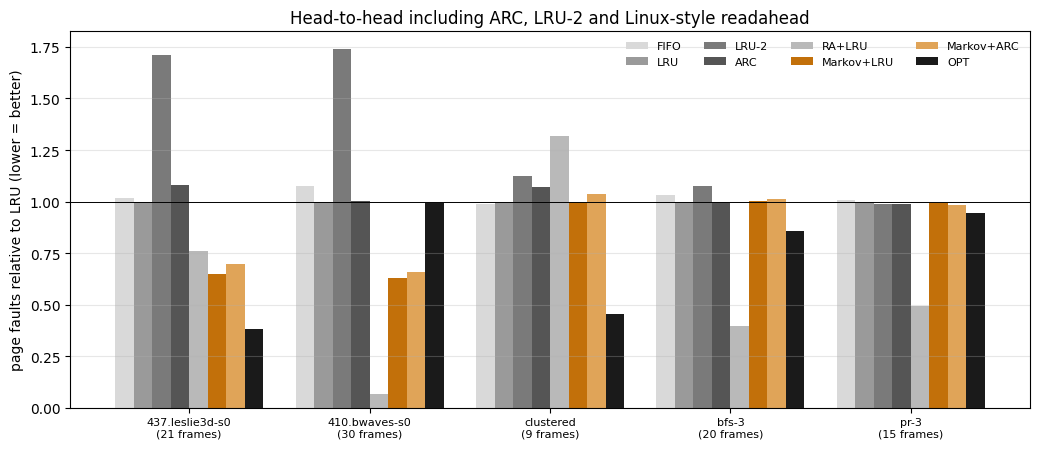

saved phase8_head_to_head.csv, phase8_summary.json and fig_phase8_head_to_head.png to /content/drive/MyDrive/paging_sim


In [ ]:
#cell 30 — Phase 8: what the head-to-head shows, plus figure and summary
import os, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

assert 'h8' in globals(), 'run cell 29 first'
FIG8 = f'{BASE}/figures'
os.makedirs(FIG8, exist_ok=True)

d = h8.copy()
trad = ['FIFO', 'Clock', 'LRU', 'LRU-2', 'ARC']

# Q1. does a smarter eviction policy ALONE close part of the LRU -> OPT gap?
room = (d['LRU'] - d['OPT'])
q1 = pd.DataFrame({
    'LRU->OPT gap': (room / d['LRU']).round(3),
    'LRU-2 closes': ((d['LRU'] - d['LRU-2']) / room).where(room > 0).round(3),
    'ARC closes':   ((d['LRU'] - d['ARC']) / room).where(room > 0).round(3)})
print('Q1. does a smarter eviction policy alone help?  (share of the LRU->OPT gap closed)')
display(q1)

# Q2. does prediction still add value on top of ARC?
q2 = pd.DataFrame({
    'ARC alone': d['ARC'],
    'Markov+ARC': d['Markov+ARC'],
    'gain on ARC': ((d['ARC'] - d['Markov+ARC']) / d['ARC']).round(4),
    'gain on LRU': ((d['LRU'] - d['Markov+LRU']) / d['LRU']).round(4)})
print('\nQ2. does prediction still add value on top of ARC?')
display(q2)

# Q3. does the Markov predictor beat readahead?
q3 = pd.DataFrame({
    'RA+LRU': d['RA+LRU'], 'Markov+LRU': d['Markov+LRU'],
    'Markov vs readahead': ((d['RA+LRU'] - d['Markov+LRU']) / d['RA+LRU']).round(4),
    'readahead vs LRU':    ((d['LRU'] - d['RA+LRU']) / d['LRU']).round(4)})
print('\nQ3. Markov predictor versus Linux-style readahead (positive = Markov has fewer faults)')
display(q3)

# Overall: best traditional baseline (now including ARC and LRU-2) versus our system
best_trad = d[trad].min(axis=1)
best_ours = d[['Markov+LRU', 'Markov+ARC']].min(axis=1)
overall = pd.DataFrame({'best traditional': best_trad,
                        'best of ours': best_ours,
                        'reduction': ((best_trad - best_ours) / best_trad).round(4),
                        'OPT': d['OPT']})
print('\nOverall: best traditional policy (incl. ARC, LRU-2) versus our best')
display(overall)

print('\nrank per configuration (1 = fewest faults)')
display(d[[c for c in d.columns]].rank(axis=1, method='min').astype(int))

# ---- figure: faults relative to LRU (so configurations are comparable) ----
cols = [c for c in ['FIFO', 'LRU', 'LRU-2', 'ARC', 'RA+LRU', 'Markov+LRU', 'Markov+ARC', 'OPT'] if c in d.columns]
rel = d[cols].div(d['LRU'], axis=0)
colors = {'FIFO': '#d9d9d9', 'LRU': '#9a9a9a', 'LRU-2': '#7a7a7a', 'ARC': '#555555',
          'RA+LRU': '#b9b9b9', 'Markov+LRU': '#c2700a', 'Markov+ARC': '#e0a458', 'OPT': '#1a1a1a'}
ax = rel.plot(kind='bar', figsize=(10.5, 4.6), width=0.82, color=[colors[c] for c in cols])
ax.axhline(1.0, color='black', lw=0.7)
ax.set_ylabel('page faults relative to LRU (lower = better)')
ax.set_xlabel('')
ax.set_xticklabels([f'{a}\n({b} frames)' for a, b in rel.index], rotation=0, fontsize=8)
ax.set_title('Head-to-head including ARC, LRU-2 and Linux-style readahead')
ax.grid(axis='y', alpha=.3); ax.legend(ncol=4, fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(f'{FIG8}/fig_phase8_head_to_head.png', dpi=200, bbox_inches='tight'); plt.show()

summary8 = {'faults': d.reset_index().to_dict('records'),
            'overall': overall.reset_index().to_dict('records')}
with open(f'{BASE}/phase8_summary.json', 'w') as f:
    json.dump(summary8, f, indent=2, default=str)
print('saved phase8_head_to_head.csv, phase8_summary.json and fig_phase8_head_to_head.png to', BASE)

In [ ]:
#cell 31 — Phase 8b: confidence-scaled readahead, and stream + Markov combination
# NEW cell after cell 30. Nothing earlier is modified.
import numpy as np

for nm in ('ReadaheadPredictor', 'make_predictor', 'run_prefetch_sim', 'run_prefetch_sim_ghost',
           'CostAwareGhost', 'AlwaysPrefetch', 'pure_faults'):
    assert nm in globals(), f'{nm} missing — run the earlier cells first'
assert all(hasattr(t, 'pages') for t in TRACES.values()), 're-run the TRACES rebuild cell'


class GatedReadahead(ReadaheadPredictor):
    """
    Same stream detection and window growth as cell 26, but every page it returns carries a
    CONFIDENCE that grows with the length of the confirmed run:
        conf = min(1.0, base + step * run)        (run = consecutive +1 steps seen so far)
    Why: cell 26 returns 1.0 for everything, and the decision engine's highest threshold is
    0.95, so it could never say no. Now a short chance run (as in random or clustered
    traces) has low confidence and can be blocked, while a long real stream always passes.
    """
    def __init__(self, init_window=4, max_window=32, base=0.4, step=0.1):
        super().__init__(init_window, max_window)
        self.base, self.step, self.run = base, step, 0

    def update(self, history, actual_next):
        prev = self.last
        super().update(history, actual_next)
        page = int(actual_next)
        if prev is not None:
            if page == prev + 1:   self.run += 1
            elif page != prev:     self.run = 0

    def predict(self, history, top_n=1):
        conf = min(1.0, self.base + self.step * self.run)
        return [(p, conf) for p in self.pending]


def make_gated_readahead(n_frames):
    mx = max(2, n_frames // 4)                    # same window scaling as make_readahead
    return GatedReadahead(init_window=min(4, mx), max_window=mx)


class StreamMarkov:
    """
    Two predictors, one interface.
      - while a sequential stream is being followed, return the readahead window
      - otherwise fall back to the Markov hybrid (top-1 guess)
    use_stream=False disables the readahead part, which must reproduce plain Markov exactly.
    """
    def __init__(self, n_frames, use_stream=True):
        self.ra = make_gated_readahead(n_frames)
        self.mk = make_predictor('hybrid')
        self.use_stream = use_stream
        self.n_stream = self.n_markov = 0

    def update(self, history, actual_next):
        self.mk.update(history, actual_next)
        if self.use_stream:
            self.ra.update(history, actual_next)

    def predict(self, history, top_n=1):
        if self.use_stream:
            r = self.ra.predict(history, top_n)
            if r:
                self.n_stream += 1
                return r
        r = self.mk.predict(history, top_n)
        if r:
            self.n_markov += 1
        return r

    def stats(self):
        return {'stream_calls': self.n_stream, 'markov_calls': self.n_markov, **self.ra.stats()}


# ---------------- sanity checks (fast) ----------------
# 1. stream part switched off must reproduce plain Markov + ghost exactly
t = TRACES['clustered']
a = run_prefetch_sim_ghost(t, 9, LRU, make_predictor('hybrid'), CostAwareGhost())['faults']
b = run_prefetch_sim_ghost(t, 9, LRU, StreamMarkov(9, use_stream=False), CostAwareGhost())['faults']
print(f'1. stream off vs plain Markov on clustered@9: {a} vs {b} ->', 'MATCH' if a == b else 'MISMATCH')
assert a == b

# 2. on a sequential trace the gated readahead must still remove almost every fault.
#    The decision engine caps prefetching at 35% of accesses; one prefetch per access needs
#    more than that, so we also show the result with the cap removed.
NOCAP = 1e9
if 'sequential' in TRACES:
    base = pure_faults(TRACES['sequential'], 64, LRU)
    capped = run_prefetch_sim_ghost(TRACES['sequential'], 64, LRU, make_gated_readahead(64), CostAwareGhost())['faults']
    free = run_prefetch_sim_ghost(TRACES['sequential'], 64, LRU, make_gated_readahead(64),
                                  CostAwareGhost(budget_ratio=NOCAP))['faults']
    print(f'2. sequential@64: LRU={base}, gated readahead: with 35% cap={capped}, no cap={free}')
    assert free < 0.05 * base, 'without the cap, gated readahead should remove almost every fault'
    assert capped > free, 'the cap should be what throttles a pure stream'

# 3. on a random trace it must stay out of the way
if 'random' in TRACES:
    base = pure_faults(TRACES['random'], 64, LRU)
    got = run_prefetch_sim_ghost(TRACES['random'], 64, LRU, make_gated_readahead(64), CostAwareGhost())['faults']
    print(f'3. random@64: LRU={base}, gated readahead + ghost={got}')
    assert abs(got - base) <= 0.01 * base

print('\nPhase 8b classes ready; sanity checks passed')

1. stream off vs plain Markov on clustered@9: 5798 vs 5798 -> MATCH
2. sequential@64: LRU=50000, gated readahead: with 35% cap=32523, no cap=11
3. random@64: LRU=49671, gated readahead + ghost=49670

Phase 8b classes ready; sanity checks passed


In [ ]:
#cell 32 — Phase 8b: does gating / combining fix readahead's weaknesses, and is the 35% cap hiding gains?
# About 3–5 minutes (6 shadow-engine runs per configuration). Saves after every configuration;
# re-running skips configurations already done. Delete the CSV if you change the systems below.
import os, time
import pandas as pd

for nm in ('GatedReadahead', 'StreamMarkov', 'make_gated_readahead', 'make_readahead'):
    assert nm in globals(), 'run cell 31 (and cell 26) first'
assert 'h8' in globals(), 'run cells 29 and 30 first (needs h8)'

NOCAP = 1e9                                     # budget_ratio so large the cap never binds
H8B_CSV = f'{BASE}/phase8b_results.csv'
if os.path.exists(H8B_CSV):
    rows = pd.read_csv(H8B_CSV).to_dict('records')
    done = {(r['trace'], int(r['frames'])) for r in rows}
    print(f'resuming: {len(done)} configuration(s) already saved')
else:
    rows, done = [], set()

def pack(label, s, r):
    r[label] = s['faults']
    r[label + ' pf'] = s['prefetches']
    r[label + ' prec'] = round(s['pf_precision'], 3) if s['prefetches'] else None

MAKERS = {'Markov': lambda nf: make_predictor('hybrid'),
          'RAg':    lambda nf: make_gated_readahead(nf),
          'Stream': lambda nf: StreamMarkov(nf)}

t_all = time.time()
for (tname, nf) in h8.index:
    if (tname, nf) in done or tname not in TRACES:
        continue
    t, t0 = TRACES[tname], time.time()
    r = {'trace': tname, 'frames': nf, 'accesses': len(t.pages), 'LRU': h8.loc[(tname, nf), 'LRU']}
    pack('RA+LRU', run_prefetch_sim(t, nf, LRU, make_readahead(nf), AlwaysPrefetch()), r)
    for nm, mk in MAKERS.items():
        pack(f'{nm}+LRU',        run_prefetch_sim_ghost(t, nf, LRU, mk(nf), CostAwareGhost()), r)
        pack(f'{nm}+LRU nocap',  run_prefetch_sim_ghost(t, nf, LRU, mk(nf), CostAwareGhost(budget_ratio=NOCAP)), r)
    rows.append(r)
    pd.DataFrame(rows).to_csv(H8B_CSV, index=False)
    print(f'{tname:18s} frames={nf:3d} done in {time.time() - t0:.0f}s')
print(f'\ntotal time: {(time.time() - t_all) / 60:.1f} min')

p8 = pd.DataFrame(rows).set_index(['trace', 'frames'])
SYS = ['RA+LRU', 'Markov+LRU', 'Markov+LRU nocap', 'RAg+LRU', 'RAg+LRU nocap', 'Stream+LRU', 'Stream+LRU nocap']

# ---- sanity: the two reference columns must equal what cell 29 already produced ----
for c in ['RA+LRU', 'Markov+LRU']:
    same = (p8[c] == h8.loc[p8.index, c]).all()
    print(f'check — {c} identical to cell 29:', 'MATCH' if same else 'MISMATCH (investigate)')

print('\n=== page faults (lower = better) ===')
d = p8[['LRU'] + SYS].copy()
d['OPT'] = h8.loc[p8.index, 'OPT']
display(d)

print('\n=== is the 35% prefetch cap binding?  (prefetches / (0.35 x accesses); near 1.0 = yes) ===')
display(pd.DataFrame({s: (p8[s + ' pf'] / (0.35 * p8['accesses'])).round(2)
                      for s in ['Markov+LRU', 'RAg+LRU', 'Stream+LRU']}))

print('\n=== pages loaded into RAM = faults + prefetches (the I/O bill) ===')
io = pd.DataFrame({'LRU': p8['LRU']})
for s in SYS:
    io[s] = p8[s] + p8[s + ' pf']
display(io)

print('\n=== prefetch precision (share of prefetches actually used) ===')
display(p8[[s + ' prec' for s in SYS]])

print('\n=== fault reduction vs LRU (positive = better) ===')
display(pd.DataFrame({s: ((p8['LRU'] - p8[s]) / p8['LRU']).round(4) for s in SYS}))

trad = h8.loc[p8.index, ['FIFO', 'Clock', 'LRU', 'LRU-2', 'ARC']].min(axis=1)
best = p8[SYS].min(axis=1)
print('\n=== best system vs best traditional policy (incl. ARC) ===')
display(pd.DataFrame({'best traditional': trad, 'best system': best,
                      'winner': p8[SYS].idxmin(axis=1),
                      'reduction': ((trad - best) / trad).round(4)}))

437.leslie3d-s0    frames= 21 done in 15s
410.bwaves-s0      frames= 30 done in 11s
clustered          frames=  9 done in 3s
bfs-3              frames= 20 done in 10s
pr-3               frames= 15 done in 10s

total time: 0.8 min
check — RA+LRU identical to cell 29: MATCH
check — Markov+LRU identical to cell 29: MATCH

=== page faults (lower = better) ===


,,LRU,RA+LRU,Markov+LRU,Markov+LRU nocap,RAg+LRU,RAg+LRU nocap,Stream+LRU,Stream+LRU nocap,OPT
trace,frames,,,,,,,,,
437.leslie3d-s0,21,15313,11624,9956,9954,13528,13521,8392,8386,5881
410.bwaves-s0,30,3140,204,1969,1969,205,204,208,207,3112
clustered,9,5803,7645,5798,5798,5931,5931,7132,7132,2637
bfs-3,20,7394,2924,7427,7427,2925,2924,3102,3100,6349
pr-3,15,5905,2905,5872,5872,2905,2905,2874,2874,5591



=== is the 35% prefetch cap binding?  (prefetches / (0.35 x accesses); near 1.0 = yes) ===


,,Markov+LRU,RAg+LRU,Stream+LRU
trace,frames,,,
437.leslie3d-s0,21,0.08,0.06,0.23
410.bwaves-s0,30,0.02,0.05,0.06
clustered,9,0.26,0.01,0.46
bfs-3,20,0.00,0.10,0.12
pr-3,15,0.01,0.06,0.07



=== pages loaded into RAM = faults + prefetches (the I/O bill) ===


...

,,RA+LRU prec,Markov+LRU prec,Markov+LRU nocap prec,RAg+LRU prec,RAg+LRU nocap prec,Stream+LRU prec,Stream+LRU nocap prec
trace,frames,,,,,,,
437.leslie3d-s0,21,0.334,0.939,0.939,0.447,0.448,0.455,0.455
410.bwaves-s0,30,0.859,0.875,0.875,0.859,0.859,0.757,0.757
clustered,9,0.420,0.793,0.793,0.391,0.391,0.628,0.628
bfs-3,20,0.689,0.024,0.024,0.690,0.689,0.554,0.554
pr-3,15,0.734,0.110,0.110,0.734,0.734,0.650,0.650



=== fault reduction vs LRU (positive = better) ===


,,RA+LRU,Markov+LRU,Markov+LRU nocap,RAg+LRU,RAg+LRU nocap,Stream+LRU,Stream+LRU nocap
trace,frames,,,,,,,
437.leslie3d-s0,21,0.2409,0.3498,0.3500,0.1166,0.1170,0.4520,0.4524
410.bwaves-s0,30,0.9350,0.3729,0.3729,0.9347,0.9350,0.9338,0.9341
clustered,9,-0.3174,0.0009,0.0009,-0.0221,-0.0221,-0.2290,-0.2290
bfs-3,20,0.6045,-0.0045,-0.0045,0.6044,0.6045,0.5805,0.5807
pr-3,15,0.5080,0.0056,0.0056,0.5080,0.5080,0.5133,0.5133



=== best system vs best traditional policy (incl. ARC) ===


,,best traditional,best system,winner,reduction
trace,frames,,,,
437.leslie3d-s0,21,15126,8386,Stream+LRU nocap,0.4456
410.bwaves-s0,30,3140,204,RA+LRU,0.9350
clustered,9,5676,5798,Markov+LRU,-0.0215
bfs-3,20,7368,2924,RA+LRU,0.6031
pr-3,15,5822,2874,Stream+LRU,0.5064
